In [21]:
import os

# Устанавливаем уровень логирования TensorFlow ДО импорта tensorflow
# 0 = все сообщения (по умолчанию)
# 1 = INFO сообщения отфильтрованы
# 2 = WARNING и INFO сообщения отфильтрованы
# 3 = ERROR, WARNING и INFO сообщения отфильтрованы (используйте с осторожностью)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Начните с '2'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta, timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import time
import requests

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold

# TensorFlow импортируется здесь, ПОСЛЕ установки TF_CPP_MIN_LOG_LEVEL
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

try:
    import pandas_ta as ta
except ImportError:
    print("Библиотека pandas_ta не найдена. Пожалуйста, установите ее: pip install pandas_ta")

from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

from config import api_token, TOKEN  # Убедитесь, что TOKEN это TINKOFF_API_TOKEN

import warnings

# Это подавит ВСЕ предупреждения Python, включая TqdmWarning, если оно еще не было вызвано.
# Для TqdmWarning лучше установить ipywidgets или настроить его отдельно, если возможно.
warnings.filterwarnings("ignore")  # У вас это уже есть


In [22]:
#  ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ КОНФИГУРАЦИИ

#  API Ключи
TINKOFF_API_TOKEN = TOKEN
NEWSAPI_KEY = api_token
NEWSAPI_KEY_DEFAULT_PLACEHOLDER = "YOUR_NEWSAPI_KEY_PLACEHOLDER"  # Значение по умолчанию, если ключ не задан в config.py

#  Параметры инструмента и общие для моделей
INSTRUMENT_FIGI = "BBG004730N88"  # SBER
FEATURE_COLUMN = 'close'  # Целевая колонка для прогнозирования цены
Z_SCORE_THRESHOLD = 3  # Порог для удаления выбросов по Z-оценке
N_CV_SPLITS = 4  # Количество фолдов в кросс-валидации
MAX_CV_WORKERS = min(N_CV_SPLITS, (os.cpu_count() or 1) * 2)  # Потоки для CV
TEST_SPLIT_SIZE = 0.2  # Доля данных для тестовой выборки
RANDOM_STATE = 42  # Для воспроизводимости

#  Директория для сохранения CSV
OUTPUT_CSV_DIRECTORY = "future_price_predictions"

#  Параметры Технических Индикаторов (TA)
SMA_PERIODS = [1, 5, 10]
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
ATR_PERIOD = 14
BBANDS_PERIOD = 20
BBANDS_STD_DEV = 2
RSI_PERIOD = 14
STOCH_K = 14
STOCH_D = 3
STOCH_SMOOTH_K = 3

#  Конфигурация для новостей (NewsAPI)
NEWSAPI_BASE_URL_EVERYTHING = "https://newsapi.org/v2/everything"
NEWS_API_PAGE_SIZE = 100  # NewsAPI позволяет до 100
NEWSAPI_HISTORY_LIMIT_DAYS = 28
NEWSAPI_MAX_PAGES_PER_DAY = 5  # Ограничение на количество страниц при пагинации за день (100 * 5 = 500 новостей)

# Глобальные переменные для модели анализа тональности (News)
SENTIMENT_MODEL_NAME = "MonoHime/rubert-base-cased-sentiment-new"
sentiment_tokenizer = None
sentiment_model = None
sentiment_device = None
sentiment_model_loaded = False
sentiment_model_lock = Lock()

#  Общий Lock для вывода в консоль
print_lock = Lock()

#  Графики
MAX_GAP_MULTIPLIER_FOR_PLOT = 1.0  # Если разрыв > timeframe * multiplier, сжимаем

# Настройка GPU для TensorFlow
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        with print_lock:
            print(f"Enabled memory growth for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        with print_lock:
            print(f"Error setting memory growth: {e}. Must be set before GPU init.")



In [23]:
#  БЛОК НОВОСТЕЙ: Функции для обработки новостей (адаптировано для NewsAPI)

def load_sentiment_model_if_needed(p_lock: Lock):
    global sentiment_tokenizer, sentiment_model, sentiment_device, sentiment_model_loaded
    if sentiment_model_loaded:
        return True
    with sentiment_model_lock:
        if sentiment_model_loaded:
            return True
        try:
            with p_lock:
                print(f"[NEWS_SENTIMENT_LOADER] Начало загрузки модели анализа тональности: {SENTIMENT_MODEL_NAME}...")
            sentiment_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_NAME)
            sentiment_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL_NAME)
            sentiment_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            sentiment_model.to(sentiment_device)
            sentiment_model.eval()
            sentiment_model_loaded = True
            with p_lock:
                print(
                    f"[NEWS_SENTIMENT_LOADER] Модель {SENTIMENT_MODEL_NAME} успешно загружена на устройство: {sentiment_device}.")
            return True
        except Exception as e:
            with p_lock:
                print(
                    f"[NEWS_SENTIMENT_LOADER] КРИТИЧЕСКАЯ ОШИБКА: Не удалось загрузить модель анализа тональности {SENTIMENT_MODEL_NAME}. Ошибка: {e}")
            sentiment_model_loaded = False
            return False


def analyze_batch_sentiment(texts: list, p_lock: Lock):
    if not sentiment_model_loaded:
        if not load_sentiment_model_if_needed(p_lock):
            with p_lock:
                print("[NEWS_ANALYZER] Модель тональности не загружена. Анализ тональности невозможен.")
            return [0] * len(texts)

    inputs = sentiment_tokenizer(texts, return_tensors="pt", truncation=True, padding=True, max_length=512)
    inputs = {k: v.to(sentiment_device) for k, v in inputs.items()}
    sentiment_scores = []
    try:
        with torch.no_grad():
            outputs = sentiment_model(**inputs)
            predictions = torch.argmax(outputs.logits, dim=-1)
        for pred_idx in predictions:
            label = sentiment_model.config.id2label[pred_idx.item()]
            if label == 'positive':
                sentiment_scores.append(1)
            elif label == 'negative':
                sentiment_scores.append(-1)
            else:
                sentiment_scores.append(0)
    except Exception as e:
        with p_lock:
            print(f"[NEWS_ANALYZER] Ошибка во время анализа тональности батча: {e}")
        return [0] * len(texts)
    return sentiment_scores


def get_search_query_for_instrument(instrument_identifier: str, p_lock: Lock) -> str:
    if instrument_identifier == "BBG004730N88":  # SBER
        query = '"Сбербанк" OR "SBER"'
        with p_lock: print(
            f"[NEWS_QUERY_HELPER] Для FIGI {instrument_identifier} используется поисковый запрос: {query}")
        return query
    with p_lock:
        print(
            f"[NEWS_QUERY_HELPER] ВНИМАНИЕ: Для инструмента '{instrument_identifier}' не найдено специального маппинга. Используется как есть. Это может быть неэффективно для NewsAPI, если это FIGI.")
    return instrument_identifier


def fetch_real_news_from_newsapi(search_query: str,
                                 date_from_iso: str,
                                 date_to_iso: str,
                                 page_num: int,
                                 current_api_key: str,
                                 p_lock: Lock,
                                 model_name_prefix_for_log: str = ""):
    params = {
        'apiKey': current_api_key,
        'q': search_query,
        'from': date_from_iso,
        'to': date_to_iso,
        'language': 'ru',
        'sortBy': 'publishedAt',
        'pageSize': NEWS_API_PAGE_SIZE,
        'page': page_num
    }
    log_prefix = f"[{model_name_prefix_for_log}]" if model_name_prefix_for_log else ""
    masked_params_for_log = params.copy()
    if current_api_key and current_api_key != NEWSAPI_KEY_DEFAULT_PLACEHOLDER:
        masked_params_for_log['apiKey'] = "***API_KEY***"
    try:
        prepared_request = requests.Request('GET', NEWSAPI_BASE_URL_EVERYTHING, params=masked_params_for_log).prepare()
        full_url_for_log = prepared_request.url
    except Exception as e_url:
        full_url_for_log = f"{NEWSAPI_BASE_URL_EVERYTHING}?params=... (ошибка сборки URL для лога: {e_url})"

    with p_lock:
        print(f"{log_prefix}[NEWS_API_REQUEST] Запрос (страница {page_num}) на URL: {full_url_for_log}")

    if not current_api_key or current_api_key == NEWSAPI_KEY_DEFAULT_PLACEHOLDER:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_STUB] ЗАГЛУШКА: API ключ NewsAPI не настроен или является плейсхолдером. Мок-ответ для '{search_query}', {date_from_iso} - {date_to_iso}, стр. {page_num}.")
        mock_news_articles = []
        num_mock_news = np.random.randint(0, min(5, NEWS_API_PAGE_SIZE // 2))
        try:
            base_ts = pd.Timestamp(date_from_iso.split('T')[0])
            for i in range(num_mock_news):
                h, m, s = np.random.randint(0, 24), np.random.randint(0, 60), np.random.randint(0, 60)
                news_ts = base_ts.replace(hour=h, minute=m, second=s)
                sentiment_type = np.random.choice(["positive", "negative", "neutral"])
                mock_news_articles.append({
                    "publishedAt": news_ts.isoformat(timespec='seconds') + "Z",
                    "title": f"Mock NewsAPI Title {i + 1} ({sentiment_type}) for {search_query}",
                    "description": f"Mock NewsAPI description for {search_query} ({sentiment_type}). " + "word " * 15,
                    "content": f"Mock NewsAPI content for {search_query} ({sentiment_type}). " + "word " * 10 + "[+50 chars]",
                    "source": {"name": "MockSource"}
                })
        except Exception as e_mock:
            with p_lock:
                print(f"{log_prefix}[NEWS_STUB] Ошибка генерации мок-данных NewsAPI: {e_mock}")
        return mock_news_articles, len(mock_news_articles)

    try:
        response = requests.get(NEWSAPI_BASE_URL_EVERYTHING, params=params, timeout=45)
        response.raise_for_status()
        data = response.json()
        if data.get('status') == 'ok':
            return data.get('articles', []), data.get('totalResults', 0)
        else:
            api_error_code = data.get('code', 'UnknownCode');
            api_error_message = data.get('message', 'Unknown error from NewsAPI')
            with p_lock:
                print(
                    f"{log_prefix}[NEWS_API_ERROR] Ошибка от NewsAPI для '{search_query}' ({date_from_iso}-{date_to_iso}): Code: {api_error_code}, Message: {api_error_message}")
            return [], 0
    except requests.exceptions.HTTPError as e:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_API_ERROR] HTTP ошибка для '{search_query}' ({date_from_iso}-{date_to_iso}): {e}. Ответ: {e.response.text[:200] if e.response else 'N/A'}")
    except requests.exceptions.RequestException as e:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_API_ERROR] Сетевая ошибка для '{search_query}' ({date_from_iso}-{date_to_iso}): {e}")
    except ValueError as e:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_API_ERROR] Ошибка декодирования JSON для '{search_query}' ({date_from_iso}-{date_to_iso}): {e}")
    except Exception as e:
        with p_lock:
            print(
                f"{log_prefix}[NEWS_API_ERROR] Неизвестная ошибка для '{search_query}' ({date_from_iso}-{date_to_iso}): {e}")
    return [], 0


def fetch_day_news_with_pagination(search_query: str, target_date_pd: pd.Timestamp, current_api_key: str, p_lock: Lock,
                                   model_name_prefix: str):
    date_from_api_str = target_date_pd.strftime('%Y-%m-%dT00:00:00')
    date_to_api_str = target_date_pd.strftime('%Y-%m-%dT23:59:59')
    all_articles_for_day = []
    current_page = 1
    total_results_for_query = 0
    log_prefix_day_fetch = f"[{model_name_prefix}][NEWS_DAY_FETCHER:{target_date_pd.strftime('%Y-%m-%d')}]"

    while current_page <= NEWSAPI_MAX_PAGES_PER_DAY:
        articles_page, total_results_on_page = fetch_real_news_from_newsapi(
            search_query, date_from_api_str, date_to_api_str, current_page,
            current_api_key, p_lock, model_name_prefix
        )
        if current_page == 1:
            total_results_for_query = total_results_on_page
            if total_results_for_query == 0 and not articles_page:
                with p_lock: print(f"{log_prefix_day_fetch} Новостей не найдено (totalResults=0).")
                break
        if not articles_page:
            with p_lock: print(
                f"{log_prefix_day_fetch} Страница {current_page} не вернула статей. Завершение пагинации.")
            break
        all_articles_for_day.extend(articles_page)
        if len(all_articles_for_day) >= total_results_for_query or len(articles_page) < NEWS_API_PAGE_SIZE:
            with p_lock: print(
                f"{log_prefix_day_fetch} Пагинация завершена на стр. {current_page}. Собрано {len(all_articles_for_day)}/{total_results_for_query} статей.")
            break
        current_page += 1
        if current_page > NEWSAPI_MAX_PAGES_PER_DAY:
            with p_lock: print(
                f"{log_prefix_day_fetch} Достигнут лимит страниц ({NEWSAPI_MAX_PAGES_PER_DAY}) для пагинации. Собрано {len(all_articles_for_day)} статей.")
    return all_articles_for_day


def process_instrument_news(instrument_identifier: str,
                            news_fetch_days_param: int,
                            candle_interval_timedelta: timedelta,
                            p_lock: Lock,
                            model_name_prefix: str = ""):
    output_columns = ['news_sentiment_mean', 'news_sentiment_sum', 'news_count', 'news_positive_count',
                      'news_negative_count', 'news_neutral_count']
    empty_df_result = pd.DataFrame(columns=output_columns).set_index(pd.DatetimeIndex([]))
    for col in output_columns: empty_df_result[col] = pd.Series(dtype=int if 'count' in col else float)
    if not load_sentiment_model_if_needed(p_lock): return empty_df_result

    search_query = get_search_query_for_instrument(instrument_identifier, p_lock)
    end_datetime_utc_naive = (pd.Timestamp.now(tz=timezone.utc).normalize() + timedelta(days=1) - timedelta(
        microseconds=1)).tz_localize(None)
    requested_start_date_naive = (
            pd.Timestamp.now(tz=timezone.utc).normalize() - timedelta(days=news_fetch_days_param)).tz_localize(None)
    earliest_possible_start_date_newsapi_naive = (
            pd.Timestamp.now(tz=timezone.utc).normalize() - timedelta(days=NEWSAPI_HISTORY_LIMIT_DAYS)).tz_localize(
        None)
    start_datetime_utc_naive = max(requested_start_date_naive, earliest_possible_start_date_newsapi_naive)
    log_prefix_news = f"[{model_name_prefix}][NEWS_PROCESSOR]"

    with p_lock:
        print(
            f"{log_prefix_news} Запуск обработки новостей для запроса: '{search_query}' (исходный идентификатор: {instrument_identifier}).")
        if requested_start_date_naive < earliest_possible_start_date_newsapi_naive:
            print(
                f"{log_prefix_news} ВНИМАНИЕ: Запрошенная история новостей ({news_fetch_days_param} дней) превышает лимит NewsAPI ({NEWSAPI_HISTORY_LIMIT_DAYS} дней для бесплатного тарифа). Новости будут запрошены начиная с {start_datetime_utc_naive.strftime('%Y-%m-%d')}.")
        print(
            f"{log_prefix_news} Запрошенный период для новостей (UTC naive): С: {start_datetime_utc_naive.strftime('%Y-%m-%d %H:%M:%S')} ПО: {end_datetime_utc_naive.strftime('%Y-%m-%d %H:%M:%S')}")

    processed_raw_news = []
    current_api_request_date = start_datetime_utc_naive.normalize()
    loop_end_api_request_date = end_datetime_utc_naive.normalize()
    dates_to_fetch_for_api = []
    while current_api_request_date <= loop_end_api_request_date:
        dates_to_fetch_for_api.append(current_api_request_date)
        current_api_request_date += timedelta(days=1)
    if not dates_to_fetch_for_api:
        with p_lock: print(f"{log_prefix_news} Нет дат для запроса новостей.")
        return empty_df_result

    max_workers_news_fetch = min(8, len(dates_to_fetch_for_api), (os.cpu_count() or 1) * 2)
    with ThreadPoolExecutor(max_workers=max_workers_news_fetch,
                            thread_name_prefix=f"{model_name_prefix}_NewsFetch") as executor:
        future_to_date = {executor.submit(fetch_day_news_with_pagination, search_query, fetch_date, NEWSAPI_KEY, p_lock,
                                          model_name_prefix): fetch_date for fetch_date in dates_to_fetch_for_api}
        for future in as_completed(future_to_date):
            fetch_date = future_to_date[future]
            try:
                daily_news_items = future.result()
                if daily_news_items:
                    for news_item in daily_news_items:
                        try:
                            title = news_item.get('title', '');
                            description = news_item.get('description', '')
                            text_content = f"{title} {description}".strip()
                            if not text_content:
                                text_content = news_item.get('content', '')
                                if text_content and "[+" in text_content and text_content.endswith(
                                        "chars]"): text_content = text_content[:text_content.rfind("[+")]
                                text_content = text_content.strip()
                            if not text_content: continue
                            ts_str = news_item.get('publishedAt')
                            if not ts_str: continue
                            timestamp = pd.to_datetime(ts_str, errors='coerce')
                            if pd.isna(timestamp):
                                with p_lock: print(
                                    f"{log_prefix_news} Не удалось распознать дату: {ts_str} из новости: {str(news_item)[:100]}")
                                continue
                            if timestamp.tzinfo is not None:
                                timestamp = timestamp.tz_convert('UTC').tz_localize(None)
                            else:
                                timestamp = timestamp.tz_localize('UTC').tz_localize(None)
                            if not (start_datetime_utc_naive <= timestamp <= end_datetime_utc_naive): continue
                            processed_raw_news.append({'time': timestamp, 'text': text_content})
                        except Exception as e_item:
                            with p_lock:
                                print(
                                    f"{log_prefix_news} Ошибка парсинга полей новости NewsAPI: {str(news_item)[:200]}. Детали: {e_item}")
            except Exception as e_future:
                with p_lock:
                    print(
                        f"{log_prefix_news} Ошибка получения новостей за {fetch_date.strftime('%Y-%m-%d')}: {e_future}")

    if not processed_raw_news:
        with p_lock: print(
            f"{log_prefix_news} Новости для запроса '{search_query}' не найдены или не прошли обработку.")
        return empty_df_result

    with p_lock:
        print(
            f"{log_prefix_news} Получено {len(processed_raw_news)} новостей для анализа тональности (запрос: '{search_query}').")
    processed_raw_news.sort(key=lambda x: x['time'])
    news_texts_for_analysis = [item['text'] for item in processed_raw_news]
    news_timestamps_for_analysis = [item['time'] for item in processed_raw_news]

    sentiment_batch_size = 32
    all_sentiment_scores = []
    for i in range(0, len(news_texts_for_analysis), sentiment_batch_size):
        batch_texts = news_texts_for_analysis[i:i + sentiment_batch_size]
        if not batch_texts: continue
        all_sentiment_scores.extend(analyze_batch_sentiment(batch_texts, p_lock))

    analyzed_news_data = []
    if len(all_sentiment_scores) == len(news_timestamps_for_analysis):
        for i in range(len(all_sentiment_scores)):
            analyzed_news_data.append(
                {'time': news_timestamps_for_analysis[i], 'sentiment_score': all_sentiment_scores[i]})
    else:
        with p_lock:
            print(
                f"{log_prefix_news} ОШИБКА: несоответствие длин времен ({len(news_timestamps_for_analysis)}) и оценок ({len(all_sentiment_scores)}).")
        return empty_df_result
    if not analyzed_news_data:
        with p_lock: print(f"{log_prefix_news} Нет данных после анализа тональности.")
        return empty_df_result

    news_df = pd.DataFrame(analyzed_news_data)
    if news_df.empty:
        with p_lock: print(f"{log_prefix_news} DataFrame новостей пуст после анализа.")
        return empty_df_result
    news_df.set_index('time', inplace=True)

    total_seconds = candle_interval_timedelta.total_seconds()
    if total_seconds <= 0:
        with p_lock: print(f"{log_prefix_news} Ошибка: интервал свечей <= 0 ({total_seconds}s).")
        return empty_df_result
    resample_rule_parts = []
    days_td, rem_sec = divmod(total_seconds, 86400);  # Renamed 'days' to 'days_td' to avoid conflict with datetime.days
    hours, rem_sec = divmod(rem_sec, 3600);
    mins, secs = divmod(rem_sec, 60)
    if days_td > 0: resample_rule_parts.append(f"{int(days_td)}D")
    if hours > 0: resample_rule_parts.append(f"{int(hours)}H")
    if mins > 0: resample_rule_parts.append(f"{int(mins)}min")
    if secs > 0: resample_rule_parts.append(f"{int(secs)}S")
    if not resample_rule_parts:
        if total_seconds > 0:
            resample_rule = f"{int(total_seconds)}S"
        else:
            with p_lock:
                print(f"{log_prefix_news} Не удалось определить правило resample для {candle_interval_timedelta}.")
            return empty_df_result
    else:
        resample_rule = "".join(resample_rule_parts)

    try:
        aggregated_news_df = news_df['sentiment_score'].resample(rule=resample_rule, closed='left', label='left').agg(
            news_sentiment_mean='mean', news_sentiment_sum='sum', news_count='count',
            news_positive_count=lambda x: (x > 0).sum(), news_negative_count=lambda x: (x < 0).sum(),
            news_neutral_count=lambda x: (x == 0).sum()
        )
    except Exception as e_resample:
        with p_lock:
            print(f"{log_prefix_news} Ошибка ресемплинга новостей по правилу '{resample_rule}': {e_resample}")
        return empty_df_result

    if 'news_sentiment_mean' in aggregated_news_df.columns: aggregated_news_df['news_sentiment_mean'] = \
        aggregated_news_df['news_sentiment_mean'].fillna(0)
    aggregated_news_df = aggregated_news_df.fillna(0)
    for col in output_columns:
        if col not in aggregated_news_df: aggregated_news_df[col] = 0
        if 'count' in col:
            aggregated_news_df[col] = aggregated_news_df[col].astype(int)
        elif 'mean' in col or 'sum' in col:
            aggregated_news_df[col] = aggregated_news_df[col].astype(float)
    with p_lock:
        print(
            f"{log_prefix_news} Агрегировано {len(aggregated_news_df)} записей новостных признаков (интервал: {resample_rule}).")
    return aggregated_news_df[output_columns]



In [24]:
#  БЛОК 0: Вспомогательные функции (Общие и для Tinkoff)

def format_metrics_for_plot(metrics_dict: dict, model_name_for_title: str = ""):
    """Форматирует словарь метрик в строку для отображения на графике."""
    if not metrics_dict:
        return f"[{model_name_for_title}]\nМетрики недоступны."

    lines = [f"Метрики для \"{model_name_for_title}\":"] if model_name_for_title else ["Метрики:"]

    # Определяем порядок и наличие основных метрик
    metric_order = ['mae', 'mae_pct', 'rmse', 'rmse_pct', 'mse', 'mse_pct', 'r2', 'r2_pct']
    available_metrics = {k: metrics_dict[k] for k in metric_order if k in metrics_dict}

    for name, val in available_metrics.items():
        if pd.isna(val):
            lines.append(f"  {name.upper()}: N/A")
        elif name.endswith('_pct'):
            lines.append(f"  {name.upper()}: {val:.2f}%")
        else:
            lines.append(f"  {name.upper()}: {val:.4f}")

    # Добавляем остальные метрики, если они есть и не были включены
    for name, val in metrics_dict.items():
        if name not in available_metrics:  # чтобы избежать дублирования
            if pd.isna(val):
                lines.append(f"  {name.upper()}: N/A")
            elif isinstance(val, float) and (name.endswith('_pct') or 'percent' in name.lower()):
                lines.append(f"  {name.upper()}: {val:.2f}%")
            elif isinstance(val, float):
                lines.append(f"  {name.upper()}: {val:.4f}")
            else:
                lines.append(f"  {name.upper()}: {val}")

    return "\n".join(lines)


def save_predictions_to_csv(
        future_predictions_df: pd.DataFrame,
        model_name: str,
        instrument_figi: str,
        target_feature_name: str,
        candle_interval_name: str,
        output_dir: str = OUTPUT_CSV_DIRECTORY,
        p_lock: Lock = print_lock
):
    log_prefix_csv = f"[{model_name}][CSV_SAVE]"
    if future_predictions_df is None or future_predictions_df.empty:
        with p_lock: print(f"{log_prefix_csv} DataFrame с прогнозами пуст. CSV-файл не будет создан.")
        return
    try:
        os.makedirs(output_dir, exist_ok=True)
        timestamp_str = datetime.now().strftime("%Y%m%d_%H%M%S")
        filename = f"predictions_{instrument_figi}_{model_name}_{timestamp_str}.csv"
        filepath = os.path.join(output_dir, filename)
        df_to_save = future_predictions_df.copy()
        df_to_save.reset_index(inplace=True)
        df_to_save['model_name'] = model_name
        df_to_save['instrument_figi'] = instrument_figi
        df_to_save['target_feature'] = target_feature_name
        df_to_save['candle_interval'] = candle_interval_name
        df_to_save['prediction_made_at_utc'] = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S %Z')
        df_to_save.rename(
            columns={'datetime': 'future_timestamp_utc', 'predicted_value': f'predicted_{target_feature_name}'},
            inplace=True)
        ordered_columns = ['model_name', 'instrument_figi', 'target_feature', 'candle_interval',
                           'prediction_made_at_utc', 'future_timestamp_utc', f'predicted_{target_feature_name}']
        # Добавляем отсутствующие колонки, если их нет, чтобы reindex не вызвал ошибку
        for col in ordered_columns:
            if col not in df_to_save.columns:
                df_to_save[col] = pd.NA  # или другое значение по умолчанию
        df_to_save = df_to_save.reindex(columns=ordered_columns)
        df_to_save.to_csv(filepath, index=False, encoding='utf-8')
        with p_lock:
            print(f"{log_prefix_csv} Прогнозы успешно сохранены в файл: {filepath}")
    except Exception as e:
        with p_lock:
            print(f"{log_prefix_csv} ОШИБКА при сохранении прогнозов в CSV: {e}")
            import traceback;
            print(traceback.format_exc())


def get_timedelta_from_candle_interval(interval: CandleInterval) -> timedelta:
    mapping = {
        CandleInterval.CANDLE_INTERVAL_1_MIN: timedelta(minutes=1),
        CandleInterval.CANDLE_INTERVAL_5_MIN: timedelta(minutes=5),
        CandleInterval.CANDLE_INTERVAL_10_MIN: timedelta(minutes=10),
        CandleInterval.CANDLE_INTERVAL_15_MIN: timedelta(minutes=15),
        CandleInterval.CANDLE_INTERVAL_30_MIN: timedelta(minutes=30),
        CandleInterval.CANDLE_INTERVAL_HOUR: timedelta(hours=1),
        CandleInterval.CANDLE_INTERVAL_2_HOUR: timedelta(hours=2),
        CandleInterval.CANDLE_INTERVAL_4_HOUR: timedelta(hours=4),
        CandleInterval.CANDLE_INTERVAL_DAY: timedelta(days=1), CandleInterval.CANDLE_INTERVAL_WEEK: timedelta(weeks=1),
        CandleInterval.CANDLE_INTERVAL_MONTH: timedelta(days=30)  # Приблизительно
    }
    if interval in mapping:
        return mapping[interval]
    else:
        with print_lock:
            print(f"Предупреждение: Неизвестный интервал свечи {interval}, используется 1 минута по умолчанию.")
        return timedelta(minutes=1)


def generate_plotted_times_and_values(real_timestamps, values, timeframe_timedelta_expected,
                                      max_gap_multiplier=MAX_GAP_MULTIPLIER_FOR_PLOT):
    if not hasattr(real_timestamps, '__len__') or len(real_timestamps) == 0: return np.array([]), np.array([])
    if not hasattr(values, '__len__') or len(values) == 0: return np.array([]), np.array([])
    if len(real_timestamps) != len(values):
        with print_lock: print(
            f"ERROR in generate_plotted_times_and_values: Length mismatch ({len(real_timestamps)} vs {len(values)}). Returning empty.")
        return np.array([]), np.array([])

    real_timestamps_pd = pd.to_datetime(real_timestamps)
    values_np = np.asarray(values)

    if len(real_timestamps_pd) == 0:
        return np.array([]), np.array([])

    plotted_ts_list = [real_timestamps_pd[0]]
    plotted_values_list = [values_np[0]]

    current_plotted_time = real_timestamps_pd[0]

    for i in range(1, len(real_timestamps_pd)):
        # Разница во времени между текущей и предыдущей РЕАЛЬНОЙ меткой времени
        actual_time_diff_between_real_points = real_timestamps_pd[i] - real_timestamps_pd[i - 1]

        if actual_time_diff_between_real_points > timeframe_timedelta_expected * max_gap_multiplier:
            # Обнаружен большой разрыв: "склеиваем", продвигая время на графике на один стандартный таймфрейм
            current_plotted_time += timeframe_timedelta_expected
        else:
            # Маленький или отсутствующий разрыв: продвигаем время на графике на фактическую разницу во времени
            current_plotted_time += actual_time_diff_between_real_points

        plotted_ts_list.append(current_plotted_time)
        plotted_values_list.append(values_np[i])  # Используем значение текущей реальной точки

    return np.array(plotted_ts_list), np.array(plotted_values_list)



In [25]:
#  БЛОК 1: Загрузка и первичная обработка данных (Tinkoff Свечи и TA)
def get_tinkoff_candles(token, figi, days_history, interval, model_name=""):
    log_prefix_candles = f"[{model_name}][CANDLES_TINKOFF]"
    with print_lock:
        print(f"{log_prefix_candles} Загрузка данных: {days_history} дней, интервал {interval.name}")

    def fetch_day_data(day_offset):
        # Tinkoff API ожидает время UTC
        # Корректируем to, чтобы захватить полный предыдущий день, если day_offset > 0
        # Для day_offset = 0, to = now(), from_ = now() - 1 day (для свежести)
        # Для day_offset = 1, to = now() - 1 day, from_ = now() - 2 days

        # Целевая дата для запроса (конец дня)
        target_date_end = now().replace(hour=0, minute=0, second=0, microsecond=0) - timedelta(days=day_offset)
        # Начало дня для запроса
        target_date_start = target_date_end - timedelta(days=1)

        # Для самого свежего дня (day_offset=0) можно использовать `to=now()`
        # и `from_` на день раньше, чтобы получить самые актуальные данные, включая текущий день.
        # Однако, API может возвращать свечи только для завершенных интервалов.
        # Использование фиксированных границ дня более предсказуемо.

        # Переопределяем для большей консистентности: запрашиваем данные ЗА день D-offset
        # from_ = начало дня (D-offset), to_ = конец дня (D-offset)
        # Пример: day_offset=0 -> "сегодня", day_offset=1 -> "вчера"

        # from_ должен быть началом периода, to_ - концом.
        # `to` - по какое время нужны данные (не включительно для некоторых API, но Tinkoff обычно включает)
        # `from_` - с какого времени нужны данные (включительно)

        # Чтобы получить данные за конкретный день (например, 2023-10-25):
        # from_ = 2023-10-25 00:00:00 UTC
        # to_ = 2023-10-25 23:59:59 UTC (или 2023-10-26 00:00:00 UTC, зависит от API)
        # Tinkoff SDK get_all_candles сам разбивает на запросы по дню, если диапазон большой.
        # Мы хотим N дней *до* сегодняшнего.

        # Конец периода (самая ранняя точка - начало вчерашнего дня, если days_history=1)
        end_dt_sdk = now() - timedelta(days=day_offset)
        # Начало периода (на 1 день раньше конца)
        start_dt_sdk = end_dt_sdk - timedelta(days=1)

        # Коррекция для Tinkoff: он загружает свечи *до* `to` (не включая `to` для некоторых интервалов)
        # и *с* `from_` (включая `from_`).
        # Чтобы получить все свечи за день X, нужно from_=X 00:00, to_=X+1 00:00

        # Логика get_all_candles уже обрабатывает пагинацию по дням,
        # но мы все равно делаем параллельные запросы по дням для ускорения, если days_history > 1.
        # Наш day_offset: 0 = сегодня/вчера, 1 = вчера/позавчера и т.д.

        # Для ясности: Запрашиваем данные за один конкретный день, отступая от текущей даты
        day_to_fetch_start = (now() - timedelta(days=day_offset + 1)).replace(hour=0, minute=0, second=0, microsecond=0)
        day_to_fetch_end = (now() - timedelta(days=day_offset)).replace(hour=0, minute=0, second=0,
                                                                        microsecond=0) - timedelta(microseconds=1)

        # Если day_offset = 0, мы хотим самый свежий день
        if day_offset == 0:
            day_to_fetch_start = (now() - timedelta(days=1)).replace(hour=0, minute=0, second=0,
                                                                     microsecond=0)  # с начала вчерашнего дня
            day_to_fetch_end = now()  # по текущий момент

        try:
            with Client(token) as client:
                # Используем client.market_data.get_candles, так как get_all_candles может быть медленным
                # или иметь свои ограничения. Однако get_all_candles удобен для больших диапазонов.
                # Останемся с get_all_candles, так как он должен сам обрабатывать лимиты API.
                candles = list(client.get_all_candles(
                    figi=figi,
                    from_=day_to_fetch_start,  # Начало дня
                    to=day_to_fetch_end,  # Конец дня (или текущий момент для day_offset=0)
                    interval=interval
                ))
                return candles
        except RequestError as e:
            with print_lock:
                print(
                    f"{log_prefix_candles} Ошибка при загрузке данных за {day_to_fetch_start.date()} - {day_to_fetch_end.date()}: {e}")
            return []
        except Exception as e_generic:
            with print_lock:
                print(
                    f"{log_prefix_candles} Неизвестная ошибка при загрузке данных за {day_to_fetch_start.date()} - {day_to_fetch_end.date()}: {e_generic}")
            return []

    max_fetch_workers = min(10, days_history if days_history > 0 else 1)  # `days` переименовано в `days_history`
    all_candles_nested = []

    # Создаем список задач для ThreadPoolExecutor
    # day_offset от 0 до days_history-1
    # day_offset = 0: самый свежий доступный день (включая "сегодня", если есть данные)
    # day_offset = 1: предыдущий день, и т.д.
    futures = []
    with ThreadPoolExecutor(max_workers=max_fetch_workers, thread_name_prefix=f"{model_name}_CandleFetch") as executor:
        for day_idx in range(days_history):  # day_idx будет от 0 до days_history-1
            futures.append(executor.submit(fetch_day_data, day_idx))

        for future in as_completed(futures):
            result = future.result()
            if result: all_candles_nested.append(result)

    all_candles = [candle for sublist in all_candles_nested for candle in sublist]
    if not all_candles:
        with print_lock: print(f"{log_prefix_candles} Не удалось загрузить свечи.")
        return pd.DataFrame()
    df = pd.DataFrame([{
        'time': pd.Timestamp(c.time).tz_localize(None),  # Уже должно быть UTC от SDK, убираем tz для консистентности
        'open': float(quotation_to_decimal(c.open)),
        'high': float(quotation_to_decimal(c.high)), 'low': float(quotation_to_decimal(c.low)),
        'close': float(quotation_to_decimal(c.close)), 'volume': c.volume
    } for c in all_candles])
    if df.empty: return pd.DataFrame()
    df = df.drop_duplicates(subset=['time']).set_index('time').sort_index()
    df.dropna(inplace=True)
    with print_lock:
        print(f"{log_prefix_candles} Загружено всего {len(df)} уникальных свечей (после удаления дубликатов и NaN).")
        if not df.empty:
            print(f"{log_prefix_candles} Диапазон дат: {df.index.min()} - {df.index.max()}")
        print(f"{log_prefix_candles} Размер DataFrame после загрузки и базовой очистки: {df.shape}")
    return df


def add_technical_indicators(df: pd.DataFrame, model_name="") -> pd.DataFrame:
    log_prefix_ta = f"[{model_name}][TECH_INDICATORS]"
    is_future_ta_calc = "-future_TA" in model_name  # Проверяем, является ли это расчетом ТА для будущих данных
    if not isinstance(df.index, pd.DatetimeIndex):
        try:
            df.index = pd.to_datetime(df.index)
        except Exception as e:
            with print_lock:
                print(
                    f"{log_prefix_ta} Ошибка: Индекс DataFrame не является DatetimeIndex и не может быть преобразован: {e}")
            return df.copy()  # Возвращаем копию, чтобы избежать модификации оригинала при ошибке

    if not is_future_ta_calc:  # Логируем только для основного расчета ТА
        with print_lock: print(f"{log_prefix_ta} Добавление технических индикаторов... Исходный размер df: {df.shape}")

    df_ta = df.copy()  # Работаем с копией

    # Приведение имен колонок к нижнему регистру для pandas_ta
    rename_map = {}
    required_cols_standard = ['open', 'high', 'low', 'close', 'volume']
    for col_standard in required_cols_standard:
        if col_standard not in df_ta.columns:
            # Пытаемся найти с заглавной буквы
            if col_standard.capitalize() in df_ta.columns:
                rename_map[col_standard.capitalize()] = col_standard
            # Pandas_ta может искать 'Volume' вместо 'volume' и т.д.
            # Безопаснее всего привести все к lower case перед использованием pandas_ta

    if rename_map:  # Если нашли колонки для переименования
        df_ta.rename(columns=rename_map, inplace=True)

    # Приводим все имена колонок к нижнему регистру один раз
    df_ta.columns = df_ta.columns.str.lower()

    missing_cols_for_ta = [col for col in ['open', 'high', 'low', 'close'] if col not in df_ta.columns]
    if missing_cols_for_ta and not is_future_ta_calc:
        with print_lock: print(
            f"{log_prefix_ta} Предупреждение: Отсутствуют необходимые колонки для TA: {', '.join(missing_cols_for_ta)}. Некоторые индикаторы могут быть не рассчитаны.")

    # Расчет индикаторов
    if 'close' in df_ta.columns:
        for period in SMA_PERIODS: df_ta[f'sma_{period}'] = ta.sma(df_ta['close'], length=period)
        # MACD
        macd_df = ta.macd(df_ta['close'], fast=MACD_FAST, slow=MACD_SLOW, signal=MACD_SIGNAL)
        if macd_df is not None and not macd_df.empty:
            # pandas_ta.macd возвращает DataFrame с колонками типа MACD_12_26_9, MACDh_12_26_9, MACDs_12_26_9
            # Переименуем их для простоты, если нужно, или используем как есть
            df_ta = pd.concat([df_ta, macd_df], axis=1)

        # Bollinger Bands
        bbands_df = ta.bbands(df_ta['close'], length=BBANDS_PERIOD, std=BBANDS_STD_DEV)
        if bbands_df is not None and not bbands_df.empty:
            df_ta = pd.concat([df_ta, bbands_df],
                              axis=1)  # Колонки типа BBL_20_2.0, BBM_20_2.0, BBU_20_2.0, BBB_20_2.0, BBP_20_2.0

        # RSI
        df_ta['rsi'] = ta.rsi(df_ta['close'], length=RSI_PERIOD)

    if all(col in df_ta.columns for col in ['high', 'low', 'close']):
        # ATR
        df_ta['atr'] = ta.atr(df_ta['high'], df_ta['low'], df_ta['close'], length=ATR_PERIOD)
        # Stochastic Oscillator
        stoch_df = ta.stoch(df_ta['high'], df_ta['low'], df_ta['close'], k=STOCH_K, d=STOCH_D, smooth_k=STOCH_SMOOTH_K)
        if stoch_df is not None and not stoch_df.empty:
            df_ta = pd.concat([df_ta, stoch_df], axis=1)  # Колонки типа STOCHk_14_3_3, STOCHd_14_3_3

    if all(col in df_ta.columns for col in ['close', 'volume']):
        df_ta['obv'] = ta.obv(df_ta['close'], df_ta['volume'])
    elif not is_future_ta_calc:  # Логируем только для основного расчета ТА
        with print_lock:
            print(f"{log_prefix_ta} Предупреждение: Колонка 'volume' или 'close' отсутствует, OBV не рассчитан.")

    # VWAP (требует H, L, C, V)
    if all(col in df_ta.columns for col in ['high', 'low', 'close', 'volume']):
        # pandas_ta имеет vwap, но он может быть дневным. Рассчитаем кумулятивный для текущего датасета.
        # Если нужен "сессионный" VWAP, логика будет сложнее (сброс на начало торговой сессии).
        # Для простоты - кумулятивный VWAP по всему датасету.
        # VWAP = Cumulative (Typical Price * Volume) / Cumulative Volume
        # Typical Price = (High + Low + Close) / 3
        typical_price = (df_ta['high'] + df_ta['low'] + df_ta['close']) / 3
        df_ta['vwap'] = (typical_price * df_ta['volume']).cumsum() / df_ta['volume'].cumsum()
    elif not is_future_ta_calc:  # Логируем только для основного расчета ТА
        with print_lock:
            print(
                f"{log_prefix_ta} Предупреждение: Не удалось рассчитать VWAP, отсутствуют необходимые колонки (high, low, close, volume).")

    df_ta.replace([np.inf, -np.inf], np.nan, inplace=True)  # Замена inf на NaN перед dropna

    if not is_future_ta_calc:  # Логируем только для основного расчета ТА
        initial_nans = df_ta.isnull().sum().max()  # Максимальное количество NaN в начале из-за периодов TA
        with print_lock:
            print(
                f"{log_prefix_ta} Технические индикаторы добавлены. NaN в начале (из-за периодов TA): ~{initial_nans}")
            print(f"{log_prefix_ta} Размер df после ТА (до dropna): {df_ta.shape}")

    return df_ta


def remove_outliers_zscore(df, column_name, threshold=3, model_name=""):
    log_prefix_outliers = f"[{model_name}][OUTLIERS]"
    if column_name not in df.columns:
        with print_lock: print(f"{log_prefix_outliers} Колонка '{column_name}' не найдена для удаления выбросов.")
        return df.copy()
    series = df[column_name].astype(float)  # Убедимся, что работаем с float
    mean = series.mean();
    std = series.std()
    if std == 0 or pd.isna(std) or std < 1e-9:  # Добавлена проверка на очень малое std
        with print_lock: print(
            f"{log_prefix_outliers} Стандартное отклонение для '{column_name}' близко к нулю или NaN ({std}). Выбросы не удаляются.")
        return df.copy()
    z_scores = (series - mean) / std
    outliers_mask = np.abs(z_scores) > threshold
    num_outliers = outliers_mask.sum()
    df_cleaned = df.copy()  # Начинаем с копии
    if num_outliers > 0:
        with print_lock: print(
            f"{log_prefix_outliers} Найдено и будет удалено {num_outliers} выбросов в '{column_name}' (Z-score > {threshold}).")
        df_cleaned = df[~outliers_mask]  # Фильтруем исходный df
    return df_cleaned


def plot_data_with_outliers(original_df, cleaned_df, column_name, threshold, model_name="", timeframe_td=None):
    # Эта функция вызывается до обучения модели, поэтому метрики модели здесь не применимы.
    # Если потребуются какие-то специфичные для этого этапа "ошибки" или статистики, их можно добавить.
    # На данный момент, согласно запросу "ошибки для *соответствующей модели*", здесь они не добавляются.
    log_prefix_plot = f"[{model_name}][PLOT_OUTLIERS]"
    if original_df.empty or column_name not in original_df.columns:
        with print_lock: print(
            f"{log_prefix_plot} Невозможно построить график выбросов: DataFrame пуст или нет колонки '{column_name}'.")
        return

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)  # sharex для синхронизации оси X

    # График до удаления выбросов
    if timeframe_td is not None:
        plotted_ts_orig, mapped_values_orig = generate_plotted_times_and_values(original_df.index,
                                                                                original_df[column_name], timeframe_td)
        if len(plotted_ts_orig) > 0:
            ax1.plot(plotted_ts_orig, mapped_values_orig, label=f'Исходные ({column_name})', color='blue')
            # Отметка выбросов
            mean_orig = original_df[column_name].mean();
            std_orig = original_df[column_name].std()
            if std_orig > 0 and not pd.isna(std_orig):  # Проверка std_orig
                outliers_mask_bool = np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold
                outliers_orig_df = original_df[outliers_mask_bool]
                if not outliers_orig_df.empty:
                    # Нужно сопоставить реальные временные метки выбросов с нарисованными
                    # Это сложно, если generate_plotted_times_and_values сильно меняет временную шкалу
                    # Проще нарисовать выбросы на их реальных временных метках, если шкала не сильно сжата
                    # или использовать тот же plotted_ts_orig для фильтрации.

                    # Попробуем найти индексы выбросов в original_df.index и сопоставить с plotted_ts_orig
                    # Это нетривиально, если plotted_ts_orig имеет другую длину или NaN.
                    # Для простоты, если используется generate_plotted_times_and_values,
                    # лучше передать маску выбросов в эту функцию или рисовать на реальных временах.
                    # Пока оставим простой scatter на реальных временах, но это может не совпадать с "сжатой" линией.
                    ax1.scatter(outliers_orig_df.index, outliers_orig_df[column_name],
                                color='red', label=f'Выбросы (Z > {threshold})', s=50, zorder=5, alpha=0.7)
        else:  # Fallback
            ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name}) (fallback plot)',
                     color='blue')
    else:  # Без generate_plotted_times_and_values
        ax1.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name})', color='blue')
        mean_orig = original_df[column_name].mean();
        std_orig = original_df[column_name].std()
        if std_orig > 0 and not pd.isna(std_orig):  # Проверка std_orig
            outliers = original_df[np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold]
            if not outliers.empty: ax1.scatter(outliers.index, outliers[column_name], color='red',
                                               label=f'Выбросы (Z > {threshold})', s=50, zorder=5, alpha=0.7)
    ax1.set_title(f'[{model_name}] Данные до удаления выбросов ({column_name})');
    ax1.set_ylabel('Цена');
    ax1.legend();
    ax1.grid(True, linestyle='--', alpha=0.7)

    # График после удаления выбросов
    if not cleaned_df.empty and column_name in cleaned_df.columns:
        if timeframe_td is not None:
            plotted_ts_cleaned, mapped_values_cleaned = generate_plotted_times_and_values(cleaned_df.index,
                                                                                          cleaned_df[column_name],
                                                                                          timeframe_td)
            if len(plotted_ts_cleaned) > 0:
                ax2.plot(plotted_ts_cleaned, mapped_values_cleaned, label=f'После удаления ({column_name})',
                         color='green')
            else:  # Fallback
                ax2.plot(cleaned_df.index, cleaned_df[column_name],
                         label=f'После удаления ({column_name}) (fallback plot)', color='green')
        else:  # Без generate_plotted_times_and_values
            ax2.plot(cleaned_df.index, cleaned_df[column_name], label=f'После удаления ({column_name})', color='green')
    else:
        ax2.text(0.5, 0.5, 'Очищенные данные отсутствуют или пусты', ha='center', va='center', transform=ax2.transAxes)

    ax2.set_title(f'[{model_name}] Данные после удаления выбросов ({column_name})');
    ax2.set_xlabel('Дата/время');
    ax2.set_ylabel('Цена');
    ax2.legend();
    ax2.grid(True, linestyle='--', alpha=0.7)

    # Форматирование оси X для обоих графиков
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
    plt.setp(ax1.get_xticklabels(), rotation=30, ha="right")  # Поворот меток и для верхнего графика

    plt.tight_layout();
    plt.show()



In [26]:
#  БЛОК 2: Процесс предобработки данных (Pipeline)
def split_sequences(X_data_scaled, y_data_scaled, n_steps_in, n_steps_out, timestamps_full_data, model_name=""):
    log_prefix_seq = f"[{model_name}][SEQUENCES]"
    X, y, times_y = [], [], []
    if len(X_data_scaled) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"{log_prefix_seq} Недостаточно данных для создания последовательностей: {len(X_data_scaled)} доступно, требуется {n_steps_in + n_steps_out}")
        return np.array(X), np.array(y), np.array(times_y)
    for i in range(len(X_data_scaled) - n_steps_in - n_steps_out + 1):
        X.append(X_data_scaled[i:(i + n_steps_in), :])
        y.append(y_data_scaled[(i + n_steps_in):(i + n_steps_in + n_steps_out)])
        # Временная метка для y - это время первого прогнозируемого значения
        times_y.append(timestamps_full_data[i + n_steps_in])
    return np.array(X), np.array(y), np.array(times_y)


def preprocess_data_pipeline(
        token_tinkoff, figi_instrument, days_history_candles, interval_candles,
        target_feature_col, z_threshold_outliers,
        n_steps_in_lstm, n_steps_out_lstm,
        model_name_prefix="", plot_outliers_flag=True,
        current_candle_interval_timedelta=None,
        use_news_features_flag=True
):
    log_prefix_prep = f"[{model_name_prefix}][PREPROCESS]"
    with print_lock:
        print(f" {log_prefix_prep} Начало процесса предобработки данных ")
    df_raw_candles = get_tinkoff_candles(token_tinkoff, figi_instrument, days_history_candles, interval_candles,
                                         model_name=model_name_prefix)
    if df_raw_candles.empty:
        with print_lock: print(f"{log_prefix_prep} Ошибка: не удалось загрузить данные свечей. Предобработка прервана.")
        return None, None, None, None, None, None, None

    # Удаление выбросов перед TA может быть спорным, т.к. TA может зависеть от экстремальных значений.
    # Однако, если выбросы - это ошибки данных, их лучше убрать.
    df_cleaned_candles = remove_outliers_zscore(df_raw_candles.copy(), target_feature_col,
                                                threshold=z_threshold_outliers, model_name=model_name_prefix)

    if plot_outliers_flag and current_candle_interval_timedelta:
        # Проверяем, есть ли данные для отображения
        # plot_data_with_outliers ожидает, что df_raw_candles и df_cleaned_candles не пустые и содержат target_feature_col
        if not df_raw_candles.empty and target_feature_col in df_raw_candles.columns:
            plot_data_with_outliers(df_raw_candles, df_cleaned_candles, target_feature_col, z_threshold_outliers,
                                    model_name=model_name_prefix, timeframe_td=current_candle_interval_timedelta)
        else:
            with print_lock:
                print(
                    f"{log_prefix_prep} Пропуск plot_data_with_outliers: нет данных или колонки {target_feature_col}.")

    df_features_combined = df_cleaned_candles.copy()  # Начинаем с очищенных свечей

    if use_news_features_flag:
        with print_lock:
            print(f"{log_prefix_prep} Попытка интеграции новостных признаков...")
        if not current_candle_interval_timedelta:
            with print_lock:
                print(
                    f"{log_prefix_prep} Ошибка: current_candle_interval_timedelta не предоставлен, не могу обработать новости.")
        else:
            news_features_df = process_instrument_news(
                instrument_identifier=figi_instrument, news_fetch_days_param=days_history_candles,
                # Используем ту же историю для новостей
                candle_interval_timedelta=current_candle_interval_timedelta, p_lock=print_lock,
                model_name_prefix=model_name_prefix
            )
            if not news_features_df.empty:
                # Убедимся, что оба индекса - DatetimeIndex
                if not isinstance(df_features_combined.index, pd.DatetimeIndex):
                    df_features_combined.index = pd.to_datetime(df_features_combined.index)
                if not isinstance(news_features_df.index, pd.DatetimeIndex):
                    news_features_df.index = pd.to_datetime(news_features_df.index)

                # Объединение. Новости могут быть не для каждой свечи.
                df_features_combined = df_features_combined.merge(news_features_df, left_index=True, right_index=True,
                                                                  how='left')

                # Заполняем NaN в новостных колонках нулями (означает отсутствие новостей или нейтральный сентимент для mean)
                news_cols_to_fill = ['news_sentiment_mean', 'news_sentiment_sum', 'news_count', 'news_positive_count',
                                     'news_negative_count', 'news_neutral_count']
                for col in news_cols_to_fill:
                    if col in df_features_combined.columns:
                        df_features_combined[col] = df_features_combined[col].fillna(0)
                        # Приводим типы для согласованности
                        if 'count' in col:
                            df_features_combined[col] = df_features_combined[col].astype(int)
                        else:  # mean, sum
                            df_features_combined[col] = df_features_combined[col].astype(float)
                with print_lock:
                    print(
                        f"{log_prefix_prep} Новостные признаки успешно объединены. Размер df: {df_features_combined.shape}")
            else:
                with print_lock:
                    print(f"{log_prefix_prep} Новостные признаки не были получены или пусты. Продолжение без них.")
                    # Убедимся, что новостные колонки существуют и заполнены нулями, если модель их ожидает
                    expected_news_cols = ['news_sentiment_mean', 'news_sentiment_sum', 'news_count',
                                          'news_positive_count', 'news_negative_count', 'news_neutral_count']
                    for col in expected_news_cols:
                        if col not in df_features_combined.columns:
                            df_features_combined[col] = 0
                            if 'count' in col:
                                df_features_combined[col] = df_features_combined[col].astype(int)
                            else:
                                df_features_combined[col] = df_features_combined[col].astype(float)

    df_with_ta = add_technical_indicators(df_features_combined, model_name=model_name_prefix)

    # Удаляем строки с NaN ПОСЛЕ добавления всех признаков (ТА создает NaN в начале)
    df_full_features = df_with_ta.dropna().copy()

    with print_lock:
        print(f"{log_prefix_prep} DataFrame после добавления TA и dropna(): {df_full_features.shape}")
        if not df_full_features.empty:
            print(f"{log_prefix_prep} Колонки: {df_full_features.columns.tolist()}")
        else:
            print(f"{log_prefix_prep} DataFrame пуст после TA и dropna().")

    if df_full_features.empty or len(df_full_features) < (n_steps_in_lstm + n_steps_out_lstm):
        with print_lock: print(
            f"{log_prefix_prep} Недостаточно данных после всех обработок ({len(df_full_features)} строк), требуется как минимум {n_steps_in_lstm + n_steps_out_lstm}. Предобработка прервана.")
        return None, None, None, None, None, None, df_full_features  # Возвращаем df_full_features для возможного анализа

    # Подготовка данных для LSTM
    # Целевая переменная (y) - это 'close' (или заданная FEATURE_COLUMN)
    y_data_unscaled = df_full_features[[target_feature_col]].values

    # Признаки (X) - все колонки, включая target_feature_col (для лаговых значений)
    # Убедимся, что target_feature_col есть в df_full_features.columns
    if target_feature_col not in df_full_features.columns:
        with print_lock: print(
            f"{log_prefix_prep} КРИТИЧЕСКАЯ ОШИБКА: Целевая колонка '{target_feature_col}' отсутствует в df_full_features.")
        return None, None, None, None, None, None, df_full_features

    X_feature_names = list(df_full_features.columns)
    X_data_unscaled = df_full_features[X_feature_names].values

    with print_lock:
        print(f"{log_prefix_prep} Количество признаков для X (до масштабирования): {X_data_unscaled.shape[1]}")
        # print(f"{log_prefix_prep} Имена признаков для X: {X_feature_names}")

    # Масштабирование
    scaler_X = MinMaxScaler();
    X_data_scaled = scaler_X.fit_transform(X_data_unscaled)

    scaler_y = MinMaxScaler();
    y_data_scaled = scaler_y.fit_transform(y_data_unscaled)  # Масштабируем y (только target_feature_col)

    timestamps_for_sequences = df_full_features.index  # Временные метки для y в split_sequences

    # Создание последовательностей
    # y_data_scaled.flatten() т.к. split_sequences ожидает 1D массив для y
    X_sequences, y_sequences, times_y_sequences = split_sequences(
        X_data_scaled, y_data_scaled.flatten(),
        n_steps_in_lstm, n_steps_out_lstm, timestamps_for_sequences, model_name=model_name_prefix)

    if X_sequences.shape[0] == 0:
        with print_lock: print(f"{log_prefix_prep} Ошибка: не удалось создать обучающие последовательности X,y.")
        # Возвращаем df_full_features, чтобы его можно было использовать для отладки или если прогноз нужен на последних данных
        return None, None, None, scaler_X, scaler_y, X_feature_names, df_full_features

    with print_lock:
        print(f"{log_prefix_prep} Предобработка завершена. Создано {X_sequences.shape[0]} последовательностей.")
        print(
            f"{log_prefix_prep} Форма X_sequences: {X_sequences.shape}, Форма y_sequences: {y_sequences.shape}, Форма times_y_sequences: {times_y_sequences.shape}")
        print(f" {log_prefix_prep} Конец процесса предобработки данных \n")
    return X_sequences, y_sequences, times_y_sequences, scaler_X, scaler_y, X_feature_names, df_full_features



In [27]:
#  БЛОК 3: Построение, обучение и оценка LSTM модели
def build_lstm_model(n_steps_in, n_steps_out, n_features):
    model = Sequential([
        LSTM(70, return_sequences=True, input_shape=(n_steps_in, n_features)), Dropout(0.3),
        LSTM(70, return_sequences=False), Dropout(0.3),  # Последний LSTM не должен return_sequences=True
        Dense(50, activation='relu'), Dense(n_steps_out)
        # n_steps_out - количество выходов для прогноза на несколько шагов
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')  # Используем 'adam' и 'mse'
    return model


def calculate_regression_metrics(y_true, y_pred):
    if not hasattr(y_true, '__len__') or not hasattr(y_pred, '__len__') or \
            len(y_true) == 0 or len(y_pred) == 0 or len(y_true) != len(y_pred):
        # with print_lock: print("Предупреждение: Пустые или несовпадающие по длине y_true/y_pred в calculate_regression_metrics.")
        return {m: np.nan for m in
                ['mse', 'rmse', 'mae', 'r2', 'mape', 'smape', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}

    # Убедимся, что это numpy массивы для векторных операций
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()

    # Удаляем NaN пары, если они есть, чтобы метрики считались корректно
    valid_mask = ~ (np.isnan(y_true) | np.isnan(y_pred))
    if np.sum(valid_mask) == 0:  # Если после удаления NaN ничего не осталось
        return {m: np.nan for m in
                ['mse', 'rmse', 'mae', 'r2', 'mape', 'smape', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}

    y_true = y_true[valid_mask]
    y_pred = y_pred[valid_mask]

    if len(y_true) == 0:  # Проверка после фильтрации NaN
        return {m: np.nan for m in
                ['mse', 'rmse', 'mae', 'r2', 'mape', 'smape', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}

    mse_raw = mean_squared_error(y_true, y_pred);
    rmse_raw = np.sqrt(mse_raw);
    mae_raw = mean_absolute_error(y_true, y_pred)
    try:
        r2_raw = r2_score(y_true, y_pred)
    except ValueError:  # Может возникнуть, если y_true константный
        r2_raw = np.nan

    # MAPE и sMAPE (будьте осторожны с нулями в y_true)
    # Заменяем нули в y_true на очень маленькое число для MAPE, чтобы избежать деления на ноль,
    # но это может исказить метрику. Лучше обрабатывать это явно.
    mape = np.nan
    smape = np.nan

    # Проверяем на наличие нулей в y_true перед расчетом MAPE/sMAPE
    if not np.any(y_true == 0):
        mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
        smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100
    else:  # Если есть нули, можно либо вернуть NaN, либо использовать альтернативную обработку
        # print_lock.acquire(); print("Предупреждение: Нули в y_true, MAPE/sMAPE могут быть некорректны или NaN."); print_lock.release()
        pass  # Оставим MAPE/sMAPE как NaN в этом случае

    # Процентные метрики относительно среднего значения y_true
    mean_y_true = np.mean(y_true)
    if np.isclose(mean_y_true, 0) or pd.isna(mean_y_true):
        mse_pct, rmse_pct, mae_pct = np.nan, np.nan, np.nan
    else:
        mae_pct = (mae_raw / abs(mean_y_true)) * 100
        rmse_pct = (rmse_raw / abs(mean_y_true)) * 100
        # Для mse_pct, деление на mean_y_true**2 может быть большим, если mean_y_true мало.
        # Эта метрика менее интуитивна, чем rmse_pct или mae_pct.
        mse_val_for_pct = mean_y_true ** 2
        mse_pct = (mse_raw / mse_val_for_pct) * 100 if not np.isclose(mse_val_for_pct, 0) else np.nan

    r2_pct = r2_raw * 100 if not np.isnan(r2_raw) else np.nan

    return {'mse': mse_raw, 'rmse': rmse_raw, 'mae': mae_raw, 'r2': r2_raw,
            'mape': mape, 'smape': smape,
            'mse_pct': mse_pct, 'rmse_pct': rmse_pct, 'mae_pct': mae_pct, 'r2_pct': r2_pct}


def train_fold(fold_num, train_idx, val_idx, X_data, y_target_scaled_data,
               times_y_full_data_for_split,  # Новый аргумент
               scaler_y_obj, n_steps_in_lstm, n_steps_out_lstm, n_features_model,
               model_name_prefix="", current_n_cv_splits_val=N_CV_SPLITS):
    log_prefix_fold = f"[{model_name_prefix}][CV_FOLD]"
    with print_lock:
        print(
            f"\n {log_prefix_fold} Обучение fold {fold_num + 1}/{current_n_cv_splits_val} (признаков={n_features_model}) ")

    model_fold = build_lstm_model(n_steps_in_lstm, n_steps_out_lstm, n_features_model)

    X_train_fold, y_train_target_scaled_fold = X_data[train_idx], y_target_scaled_data[train_idx]
    X_val_fold, y_val_target_scaled_fold = X_data[val_idx], y_target_scaled_data[val_idx]

    # Получаем временные метки для валидационного набора данного фолда (для 1-го шага прогноза)
    times_y_val_fold_for_1st_step = times_y_full_data_for_split[val_idx]

    # Убедимся, что y_train_target_scaled_fold и y_val_target_scaled_fold имеют правильную форму (batch_size, n_steps_out)
    if y_train_target_scaled_fold.ndim == 1: y_train_target_scaled_fold = y_train_target_scaled_fold.reshape(-1,
                                                                                                             n_steps_out_lstm)
    if y_val_target_scaled_fold.ndim == 1: y_val_target_scaled_fold = y_val_target_scaled_fold.reshape(-1,
                                                                                                       n_steps_out_lstm)

    history_fold = model_fold.fit(X_train_fold, y_train_target_scaled_fold,
                                  validation_data=(X_val_fold, y_val_target_scaled_fold),
                                  epochs=50, batch_size=32, verbose=0,  # verbose=0 для чистоты лога в многопотоке
                                  callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

    preds_val_target_scaled_fold = model_fold.predict(X_val_fold, verbose=0)  # (n_samples, n_steps_out)

    # Оценка на 1-м шаге прогноза (самый важный для многих задач)
    # y_val_target_scaled_fold[:, 0] - это первый шаг из n_steps_out для каждого семпла валидации
    y_val_inv_1step_fold = scaler_y_obj.inverse_transform(y_val_target_scaled_fold[:, 0].reshape(-1, 1)).flatten()
    preds_val_inv_1step_fold = scaler_y_obj.inverse_transform(
        preds_val_target_scaled_fold[:, 0].reshape(-1,
                                                   1)).flatten()  # preds_val_target_scaled_fold[:, 0] - первый шаг предсказаний

    fold_metrics_dict = calculate_regression_metrics(y_val_inv_1step_fold, preds_val_inv_1step_fold)

    with print_lock:
        print(f"{log_prefix_fold} Результаты fold {fold_num + 1} (оценка на 1-м шаге прогноза):")
        for name, val in fold_metrics_dict.items():
            if not pd.isna(val):  # Печатаем только валидные метрики
                print(
                    f"  {name.upper()}: {val:.4f}{' %' if name.endswith('_pct') or name in ['mape', 'smape'] else ''}")
    return {
        'model': model_fold,
        'metrics': fold_metrics_dict,
        'history': history_fold,
        'fold': fold_num,
        'y_val_actual_inv_1step': y_val_inv_1step_fold,  # Добавлено для графика
        'y_val_pred_inv_1step': preds_val_inv_1step_fold,  # Добавлено для графика
        'times_y_val_fold_1step': times_y_val_fold_for_1st_step  # Добавлено для графика
    }


def cross_validate_lstm(X_sequences_cv, y_sequences_cv, times_y_sequences_cv,  # Новый аргумент
                        scaler_y_obj,
                        n_splits_cv, n_steps_in_lstm, n_steps_out_lstm, n_features_model,
                        model_name_prefix="", max_workers_cv=None):
    log_prefix_cv_main = f"[{model_name_prefix}][CROSS_VALIDATION]"
    effective_max_workers_cv = 0
    if n_splits_cv >= 2:
        default_cpu_workers = (os.cpu_count() or 1)  # Не умножаем на 2, т.к. обучение GPU-bound
        effective_max_workers_cv = min(n_splits_cv,
                                       max_workers_cv if max_workers_cv is not None else default_cpu_workers)
        effective_max_workers_cv = max(1, effective_max_workers_cv)  # Минимум 1 воркер

    with print_lock:
        print(
            f"\n {log_prefix_cv_main} Начало ({n_splits_cv} фолдов, до {effective_max_workers_cv} параллельных потоков) ")

    if n_splits_cv < 2:  # Кросс-валидация имеет смысл только для 2 и более фолдов
        with print_lock: print(
            f"{log_prefix_cv_main} Предупреждение: n_splits_cv = {n_splits_cv} < 2. Кросс-валидация не будет выполнена.")
        return None  # Возвращаем None, если CV не выполнена

    kf = KFold(n_splits=n_splits_cv, shuffle=True,
               random_state=RANDOM_STATE)  # shuffle=True важно для временных рядов, если нет утечки
    fold_results_list = [];
    futures_list = []

    # Убедимся, что y_sequences_cv имеет правильную форму для KFold и последующей обработки
    if y_sequences_cv.ndim == 1 and n_steps_out_lstm > 1:
        try:
            y_sequences_cv_reshaped = y_sequences_cv.reshape(-1, n_steps_out_lstm)
            if X_sequences_cv.shape[0] == y_sequences_cv_reshaped.shape[0]:
                y_sequences_cv_for_split = y_sequences_cv_reshaped
            else:
                y_sequences_cv_for_split = y_sequences_cv
                with print_lock:
                    print(
                        f"{log_prefix_cv_main} Предупреждение: форма y_sequences_cv ({y_sequences_cv.shape}) может быть неоптимальной для n_steps_out={n_steps_out_lstm}.")
        except ValueError as e_reshape:
            with print_lock:
                print(f"{log_prefix_cv_main} Ошибка reshape y_sequences_cv: {e}. Используем как есть.")
            y_sequences_cv_for_split = y_sequences_cv
    else:
        y_sequences_cv_for_split = y_sequences_cv

    with ThreadPoolExecutor(max_workers=effective_max_workers_cv,
                            thread_name_prefix=f"{model_name_prefix}_CVFold") as executor:
        for fold_num, (train_idx, val_idx) in enumerate(
                kf.split(X_sequences_cv, y_sequences_cv_for_split)):
            futures_list.append(executor.submit(train_fold, fold_num, train_idx, val_idx,
                                                X_sequences_cv,
                                                y_sequences_cv_for_split,
                                                times_y_sequences_cv,  # Передаем times_y_sequences_cv
                                                scaler_y_obj,
                                                n_steps_in_lstm, n_steps_out_lstm, n_features_model,
                                                model_name_prefix, current_n_cv_splits_val=n_splits_cv))
        for future_item in as_completed(futures_list):
            try:
                fold_results_list.append(future_item.result())
            except Exception as e_fold:
                with print_lock:
                    print(f"{log_prefix_cv_main} КРИТИЧЕСКАЯ ОШИБКА в одном из фолдов CV: {e_fold}")
                    import traceback;
                    print(traceback.format_exc())

    if not fold_results_list:  # Если ни один фолд не дал результата
        with print_lock: print(f"{log_prefix_cv_main} Кросс-валидация не дала результатов.")
        return None

    fold_results_list.sort(key=lambda r: r['fold'])  # Сортируем для консистентности, если нужно

    # Выбор лучшей модели по минимальной MSE (или другой метрике)
    best_fold_result_dict = min(fold_results_list, key=lambda r: r['metrics'].get('mse', float('inf')))

    with print_lock:
        print(f"\n {log_prefix_cv_main} Завершена ")
        print(
            f"{log_prefix_cv_main} Лучшая модель выбрана из фолда {best_fold_result_dict['fold'] + 1} (на основе MSE: {best_fold_result_dict['metrics'].get('mse', float('inf')):.4f})")
        print(f"{log_prefix_cv_main} Метрики лучшей модели (на её валидационном наборе, 1-й шаг прогноза):")
        for name, val in best_fold_result_dict['metrics'].items():
            if not pd.isna(val):
                print(
                    f"  {name.upper()}: {val:.4f}{' %' if name.endswith('_pct') or name in ['mape', 'smape'] else ''}")

    return best_fold_result_dict  # Возвращаем полный словарь результатов лучшего фолда


# Новая функция для построения графика результатов лучшего CV фолда
def plot_best_cv_fold_predictions(
        y_actual_inv_1step, y_pred_inv_1step, timestamps_1step,
        fold_metrics_dict, model_name_prefix, target_feature_name,
        timeframe_td_for_plot, fold_number):
    log_prefix_plot_cv = f"[{model_name_prefix}][CV_PLOT_FOLD_{fold_number + 1}]"
    with print_lock:
        print(f"\n {log_prefix_plot_cv} Построение графика для лучшего CV фолда (Фолд {fold_number + 1})")

    if len(y_actual_inv_1step) == 0:
        with print_lock: print(f"{log_prefix_plot_cv} Данные для графика отсутствуют.")
        return

    result_df_cv_1step = pd.DataFrame({
        'datetime': timestamps_1step,
        'actual_close_1step': y_actual_inv_1step,
        'predicted_close_1step': y_pred_inv_1step
    }).set_index('datetime').sort_index()

    plt.figure(figsize=(15, 7))
    ax_cv_fold = plt.gca()

    plot_times_actual, plot_values_actual = result_df_cv_1step.index, result_df_cv_1step['actual_close_1step'].values
    plot_times_pred, plot_values_pred = result_df_cv_1step.index, result_df_cv_1step['predicted_close_1step'].values

    if timeframe_td_for_plot is not None:
        plot_times_actual, plot_values_actual = generate_plotted_times_and_values(
            result_df_cv_1step.index, result_df_cv_1step['actual_close_1step'].values, timeframe_td_for_plot
        )
        plot_times_pred, plot_values_pred = generate_plotted_times_and_values(
            result_df_cv_1step.index, result_df_cv_1step['predicted_close_1step'].values, timeframe_td_for_plot
        )

    if len(plot_times_actual) > 0:
        ax_cv_fold.plot(plot_times_actual, plot_values_actual, label=f'Факт ({target_feature_name}, 1-й шаг)',
                        color='blue', marker='.', markersize=4, alpha=0.8)
    else:
        ax_cv_fold.plot(result_df_cv_1step.index, result_df_cv_1step['actual_close_1step'],
                        label=f'Факт ({target_feature_name}, 1-й шаг) (fallback)', color='blue')

    if len(plot_times_pred) > 0:
        ax_cv_fold.plot(plot_times_pred, plot_values_pred, label=f'Прогноз ({target_feature_name}, 1-й шаг)',
                        color='orange', linestyle='--', marker='x', markersize=4,
                        alpha=0.8)  # Изменен цвет для отличия от тестового
    else:
        ax_cv_fold.plot(result_df_cv_1step.index, result_df_cv_1step['predicted_close_1step'],
                        label=f'Прогноз ({target_feature_name}, 1-й шаг) (fallback)', color='orange', linestyle='--')

    title_parts = [
        f"[{model_name_prefix}] Факт/Прогноз ({target_feature_name}, 1-й шаг) на лучшем CV фолде (Фолд {fold_number + 1})"]

    plt.title("\n".join(title_parts), fontsize=12)
    plt.xlabel("Дата/время")
    plt.ylabel(f"Цена ({target_feature_name})")
    ax_cv_fold.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
    ax_cv_fold.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
    plt.xticks(rotation=30, ha="right")
    plt.legend(loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.7)

    metrics_text_on_plot = format_metrics_for_plot(fold_metrics_dict,
                                                   f"{model_name_prefix} (CV Фолд {fold_number + 1} - 1st step)")
    ax_cv_fold.text(0.99, 0.01, metrics_text_on_plot, transform=ax_cv_fold.transAxes,
                    fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                    bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', alpha=0.85))

    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()


def final_test_and_plot(model_final, X_test_data, y_test_target_scaled_data, scaler_y_obj,
                        times_y_test_data, n_steps_out_val, target_feature_name_val, model_name_prefix="",
                        timeframe_td_for_plot=None):
    log_prefix_final_test = f"[{model_name_prefix}][FINAL_TEST]"
    with print_lock:
        print(f"\n {log_prefix_final_test} Финальное тестирование модели ")

    if X_test_data.shape[0] == 0:
        with print_lock: print(f"{log_prefix_final_test} Тестовая выборка пуста. Финальный тест не проводится.")
        return {}  # Возвращаем пустой словарь метрик

    # Убедимся, что y_test_target_scaled_data имеет правильную форму (batch_size, n_steps_out_val)
    if y_test_target_scaled_data.ndim == 1 and n_steps_out_val > 1:
        y_test_target_scaled_data = y_test_target_scaled_data.reshape(-1, n_steps_out_val)
    elif y_test_target_scaled_data.ndim == 1 and n_steps_out_val == 1:
        y_test_target_scaled_data = y_test_target_scaled_data.reshape(-1, 1)

    preds_test_target_scaled_all = model_final.predict(X_test_data, verbose=0)  # (n_samples, n_steps_out_val)

    # Оценка на 1-м шаге прогноза
    y_test_inv_1step = scaler_y_obj.inverse_transform(y_test_target_scaled_data[:, 0].reshape(-1, 1)).flatten()
    preds_test_inv_1step = scaler_y_obj.inverse_transform(preds_test_target_scaled_all[:, 0].reshape(-1, 1)).flatten()

    test_metrics_1step_dict = calculate_regression_metrics(y_test_inv_1step, preds_test_inv_1step)

    with print_lock:
        print(f"{log_prefix_final_test} Метрики на тестовой выборке (для 1-го шага прогноза):")
        for name, val in test_metrics_1step_dict.items():
            if not pd.isna(val):
                print(
                    f"  {name.upper()}: {val:.4f}{' %' if name.endswith('_pct') or name in ['mape', 'smape'] else ''}")

    # Построение графика для 1-го шага прогноза
    result_df_1step = pd.DataFrame({
        'datetime': times_y_test_data[:len(y_test_inv_1step)],  # Убедимся, что длина совпадает
        'actual_close_1step': y_test_inv_1step,
        'predicted_close_1step': preds_test_inv_1step
    }).set_index('datetime').sort_index()

    plt.figure(figsize=(15, 7));  # Увеличим высоту для текста метрик
    ax1_test = plt.gca()

    plot_times_actual, plot_values_actual = result_df_1step.index, result_df_1step['actual_close_1step'].values
    plot_times_pred, plot_values_pred = result_df_1step.index, result_df_1step['predicted_close_1step'].values

    if timeframe_td_for_plot is not None:
        # Используем generate_plotted_times_and_values для обоих рядов, чтобы они были сопоставимы при разрывах
        plot_times_actual, plot_values_actual = generate_plotted_times_and_values(
            result_df_1step.index, result_df_1step['actual_close_1step'].values, timeframe_td_for_plot
        )
        plot_times_pred, plot_values_pred = generate_plotted_times_and_values(
            result_df_1step.index, result_df_1step['predicted_close_1step'].values, timeframe_td_for_plot
        )
        # Важно: generate_plotted_times_and_values может вернуть разную длину, если NaN вставляются.
        # Однако, если оба ряда имеют одинаковые временные метки изначально, результат должен быть согласованным.
        # Рисуем отдельно, чтобы избежать проблем с разной длиной после generate_plotted_times_and_values (хотя не должно быть)

    if len(plot_times_actual) > 0:
        ax1_test.plot(plot_times_actual, plot_values_actual, label=f'Факт ({target_feature_name_val}, 1-й шаг)',
                      color='blue', marker='.', markersize=4, alpha=0.8)
    else:  # Fallback
        ax1_test.plot(result_df_1step.index, result_df_1step['actual_close_1step'],
                      label=f'Факт ({target_feature_name_val}, 1-й шаг) (fallback)', color='blue')

    if len(plot_times_pred) > 0:
        ax1_test.plot(plot_times_pred, plot_values_pred, label=f'Прогноз ({target_feature_name_val}, 1-й шаг)',
                      color='red', linestyle='--', marker='x', markersize=4, alpha=0.8)
    else:  # Fallback
        ax1_test.plot(result_df_1step.index, result_df_1step['predicted_close_1step'],
                      label=f'Прогноз ({target_feature_name_val}, 1-й шаг) (fallback)', color='red', linestyle='--')

    mae_val = test_metrics_1step_dict.get('mae', float('nan'));
    rmse_val = test_metrics_1step_dict.get('rmse', float('nan'))
    r2_val = test_metrics_1step_dict.get('r2', float('nan'))

    title_parts_1step = [f"[{model_name_prefix}] Факт/Прогноз ({target_feature_name_val}, 1-й шаг) на тест. выборке"]
    metrics_str_parts_1step = []
    if not pd.isna(mae_val): metrics_str_parts_1step.append(f"MAE: {mae_val:.3f}")
    if not pd.isna(rmse_val): metrics_str_parts_1step.append(f"RMSE: {rmse_val:.3f}")
    if not pd.isna(r2_val): metrics_str_parts_1step.append(f"R2: {r2_val:.3f}")
    if metrics_str_parts_1step: title_parts_1step.append(" | ".join(metrics_str_parts_1step))

    plt.title("\n".join(title_parts_1step), fontsize=12);
    plt.xlabel("Дата/время");
    plt.ylabel(f"Цена ({target_feature_name_val})")
    ax1_test.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
    ax1_test.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
    plt.xticks(rotation=30, ha="right");
    plt.legend(loc='upper left');
    plt.grid(True, linestyle='--', alpha=0.7);

    # Добавление текста с метриками на график
    metrics_text_on_plot = format_metrics_for_plot(test_metrics_1step_dict, model_name_prefix + " (Test - 1st step)")
    ax1_test.text(0.99, 0.01, metrics_text_on_plot, transform=ax1_test.transAxes,
                  fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                  bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', alpha=0.85))

    plt.tight_layout(rect=[0, 0.05, 1, 0.95]);  # Оставляем место для заголовка и меток снизу
    plt.show()

    # Оценка для ПОСЛЕДНЕГО шага прогноза, если n_steps_out_val > 1
    if n_steps_out_val > 1:
        y_test_inv_last_step = scaler_y_obj.inverse_transform(y_test_target_scaled_data[:, -1].reshape(-1, 1)).flatten()
        preds_test_inv_last_step = scaler_y_obj.inverse_transform(
            preds_test_target_scaled_all[:, -1].reshape(-1, 1)).flatten()
        test_metrics_last_step_dict = calculate_regression_metrics(y_test_inv_last_step, preds_test_inv_last_step)
        with print_lock:
            print(
                f"{log_prefix_final_test} Метрики на тестовой выборке (для ПОСЛЕДНЕГО, {n_steps_out_val}-го шага прогноза):")
            for name, val in test_metrics_last_step_dict.items():
                if not pd.isna(val):
                    print(
                        f"  {name.upper()}: {val:.4f}{' %' if name.endswith('_pct') or name in ['mape', 'smape'] else ''}")
        # (можно добавить график и для последнего шага, если требуется)

    return test_metrics_1step_dict  # Возвращаем метрики для 1-го шага



In [28]:
#  БЛОК 4: Рекурсивное прогнозирование будущего
def predict_future_recursive(
        model_to_use, initial_X_sequence_scaled_val, scaler_X_obj, scaler_y_obj,
        all_X_feature_names_list, target_feature_name_val, num_total_future_steps_to_predict,
        n_steps_in_model_val, n_steps_out_model_val, last_known_full_data_df_val,  # Это df_full_features
        candle_interval_timedelta_val, model_name_prefix=""):
    log_prefix_future = f"[{model_name_prefix}][FUTURE_PREDICT]"
    with print_lock:
        print(f"\n{log_prefix_future} Запуск рекурсивного прогноза на {num_total_future_steps_to_predict} шагов...")
        print(
            f"{log_prefix_future} n_steps_in_model_val={n_steps_in_model_val}, n_steps_out_model_val={n_steps_out_model_val}")

    all_future_preds_y_inv_flat_list = []  # Собираем здесь все прогнозы y (в исходном масштабе)
    current_input_X_scaled_arr = initial_X_sequence_scaled_val.copy()  # (1, n_steps_in, n_features)

    # history_df_unscaled будет содержать последние n_steps_in_model_val реальных данных + сгенерированные будущие данные
    # Он используется для пересчета ТА на каждом шаге рекурсии.
    # Важно: он должен содержать ВСЕ КОЛОНКИ, которые были в X_feature_names исходно.
    history_df_unscaled = last_known_full_data_df_val.iloc[-n_steps_in_model_val:].copy()

    if not isinstance(history_df_unscaled.index, pd.DatetimeIndex):
        history_df_unscaled.index = pd.to_datetime(history_df_unscaled.index)

    # Проверка наличия всех нужных колонок в history_df_unscaled
    missing_cols_in_history = [col for col in all_X_feature_names_list if col not in history_df_unscaled.columns]
    if missing_cols_in_history:
        with print_lock:
            print(
                f"{log_prefix_future} ОШИБКА: В history_df_unscaled отсутствуют колонки: {missing_cols_in_history}. Прогноз невозможен.")
        return np.array([]), np.array([])

    last_real_timestamp_val = history_df_unscaled.index[-1]

    num_iterations = int(np.ceil(num_total_future_steps_to_predict / n_steps_out_model_val))
    with print_lock:
        print(f"{log_prefix_future} Потребуется итераций: {num_iterations}")

    for iter_num in range(num_iterations):
        if len(all_future_preds_y_inv_flat_list) >= num_total_future_steps_to_predict:
            # with print_lock: print(f"{log_prefix_future} Итерация {iter_num+1}: Достигнуто {len(all_future_preds_y_inv_flat_list)} прогнозов. Завершение.")
            break

        # 1. Предсказание на n_steps_out_model_val шагов вперед
        # current_input_X_scaled_arr должен быть (1, n_steps_in, n_features)
        predicted_y_scaled_chunk_arr = model_to_use.predict(current_input_X_scaled_arr, verbose=0)  # (1, n_steps_out)
        predicted_y_inv_chunk_arr = scaler_y_obj.inverse_transform(
            predicted_y_scaled_chunk_arr).flatten()  # (n_steps_out,)

        # Добавляем полученные прогнозы в общий список
        num_to_add_this_iteration = min(len(predicted_y_inv_chunk_arr),
                                        num_total_future_steps_to_predict - len(all_future_preds_y_inv_flat_list))
        all_future_preds_y_inv_flat_list.extend(predicted_y_inv_chunk_arr[:num_to_add_this_iteration])

        if len(all_future_preds_y_inv_flat_list) >= num_total_future_steps_to_predict:  # Проверка после добавления
            # with print_lock: print(f"{log_prefix_future} Итерация {iter_num+1}: Достигнуто {len(all_future_preds_y_inv_flat_list)} прогнозов после добавления. Завершение.")
            break  # Не печатаем здесь, чтобы не дублировать сообщение из конца функции

        # 2. Подготовка нового current_input_X_scaled_arr для следующей итерации
        # Обновляем history_df_unscaled, добавляя новые n_steps_out_model_val предсказанных значений

        new_rows_for_history_list = []
        current_synthetic_timestamp = history_df_unscaled.index[-1]  # Последняя известная временная метка

        for i in range(len(predicted_y_inv_chunk_arr)):  # predicted_y_inv_chunk_arr это прогнозы Y (цены закрытия)
            current_synthetic_timestamp += candle_interval_timedelta_val
            predicted_close_for_new_row = predicted_y_inv_chunk_arr[i]

            new_row_dict = {}
            # Заполняем основные OHLCV значения из предсказанного 'close'
            new_row_dict['open'] = predicted_close_for_new_row
            new_row_dict['high'] = predicted_close_for_new_row  # Упрощение
            new_row_dict['low'] = predicted_close_for_new_row  # Упрощение
            new_row_dict['close'] = predicted_close_for_new_row
            # Volume - можно взять последний известный или средний, или 0
            new_row_dict['volume'] = history_df_unscaled['volume'].iloc[
                -1] if 'volume' in history_df_unscaled.columns and not history_df_unscaled.empty else 0

            # Для остальных признаков (ТА, новости) - пока ставим NaN, они будут пересчитаны/заполнены
            for col_name_in_X in all_X_feature_names_list:
                if col_name_in_X not in new_row_dict:
                    new_row_dict[col_name_in_X] = np.nan

            new_rows_for_history_list.append(pd.DataFrame(new_row_dict, index=[current_synthetic_timestamp]))

        if not new_rows_for_history_list:
            with print_lock: print(
                f"{log_prefix_future} Итерация {iter_num + 1}: Нет новых строк для истории. Прогноз остановлен.")
            break

        # Расширяем history_df_unscaled новыми строками
        history_df_unscaled_extended_ohlcv = pd.concat([history_df_unscaled] + new_rows_for_history_list)

        # Пересчет ТА на расширенном датасете
        # Важно: TA должны рассчитываться на достаточном количестве данных.
        # Берем хвост history_df_unscaled_extended_ohlcv для пересчета TA.
        # Длина хвоста должна быть достаточной для самого длинного периода TA + n_steps_out_model_val (для стабильности)
        lookback_for_ta_recalc = max(
            [p for p in SMA_PERIODS if isinstance(p, int)] + [MACD_SLOW + MACD_SIGNAL, ATR_PERIOD, BBANDS_PERIOD,
                                                              RSI_PERIOD, STOCH_K + STOCH_SMOOTH_K, 50]  # 50 - запас
        ) + n_steps_out_model_val + 20  # +20 - доп. запас

        start_idx_for_ta_recalc = max(0, len(history_df_unscaled_extended_ohlcv) - lookback_for_ta_recalc)
        df_for_ta_recalculation = history_df_unscaled_extended_ohlcv.iloc[start_idx_for_ta_recalc:].copy()

        # Новостные признаки для будущих шагов: предполагаем, что они остаются 0 (нет новых новостей)
        # или можно было бы нести последние известные, но 0 безопаснее, если модель обучалась на 0 при отсутствии.
        news_cols_in_history = [col for col in all_X_feature_names_list if 'news_' in col]
        for ncol in news_cols_in_history:
            if ncol in df_for_ta_recalculation.columns:
                # Заполняем NaN нулями перед передачей в add_technical_indicators
                # add_technical_indicators не должен пытаться их пересчитать, если они уже есть.
                df_for_ta_recalculation[ncol] = df_for_ta_recalculation[ncol].fillna(0)

        # Пересчитываем ТА
        # model_name суффикс для add_technical_indicators, чтобы избежать подробного логирования
        df_with_new_ta_recalculated = add_technical_indicators(df_for_ta_recalculation,
                                                               model_name=f"{model_name_prefix}-future_TA")

        # Заполняем возможные NaN после ТА (особенно в начале пересчитанного куска)
        # Важно, чтобы последние n_steps_in_model_val строк не содержали NaN для X_input
        # ffill, затем bfill, затем 0 для оставшихся (если есть)
        df_with_new_ta_recalculated.fillna(method='ffill', inplace=True)
        df_with_new_ta_recalculated.fillna(method='bfill', inplace=True)
        df_with_new_ta_recalculated.fillna(0, inplace=True)  # крайний случай

        if df_with_new_ta_recalculated.empty or len(df_with_new_ta_recalculated) < n_steps_in_model_val:
            with print_lock: print(
                f"{log_prefix_future} Итерация {iter_num + 1}: Недостаточно данных ({len(df_with_new_ta_recalculated)}) после пересчета TA. Прогноз остановлен.")
            break

        # Обновляем history_df_unscaled полностью пересчитанными данными (хвост)
        # Мы не можем просто .update(), т.к. индексы могут быть новые.
        # Нужно взять последние строки из df_with_new_ta_recalculated, чтобы сформировать новый X_input
        history_df_unscaled = df_with_new_ta_recalculated.copy()  # Теперь history_df_unscaled содержит обновленные ТА

        # Формируем новый X_input из последних n_steps_in_model_val строк обновленного history_df_unscaled
        # Убедимся, что используем правильный порядок колонок all_X_feature_names_list
        new_X_unscaled_for_input_df = history_df_unscaled[all_X_feature_names_list].iloc[-n_steps_in_model_val:]

        if len(new_X_unscaled_for_input_df) < n_steps_in_model_val:
            with print_lock: print(
                f"{log_prefix_future} Итерация {iter_num + 1}: Недостаточно данных ({len(new_X_unscaled_for_input_df)}) для X_input. Прогноз остановлен.")
            break

        new_X_unscaled_values_arr = new_X_unscaled_for_input_df.values

        # Проверка на NaN перед transform (хотя выше уже должны были заполниться)
        if np.isnan(new_X_unscaled_values_arr).any():
            if (iter_num + 1) % 5 == 0:  # Логируем не на каждой итерации
                with print_lock: print(
                    f"{log_prefix_future} Итерация {iter_num + 1}: ПРЕДУПРЕЖДЕНИЕ - NaN в X_input перед масштабированием. Попытка дозаполнить.")
            temp_df_fill_nan = pd.DataFrame(new_X_unscaled_values_arr, columns=all_X_feature_names_list)
            temp_df_fill_nan = temp_df_fill_nan.fillna(method='ffill').fillna(method='bfill').fillna(0)
            new_X_unscaled_values_arr = temp_df_fill_nan.values
            if np.isnan(new_X_unscaled_values_arr).any():
                with print_lock: print(
                    f"{log_prefix_future} Итерация {iter_num + 1}: КРИТИЧЕСКАЯ ОШИБКА - NaN не устранены. Прогноз может быть неверным.")

        new_X_scaled_values_arr = scaler_X_obj.transform(new_X_unscaled_values_arr)  # (n_steps_in, n_features)
        current_input_X_scaled_arr = new_X_scaled_values_arr.reshape(1, n_steps_in_model_val,
                                                                     -1)  # (1, n_steps_in, n_features)

    future_predictions_array = np.array(all_future_preds_y_inv_flat_list)
    future_timestamps_array = pd.to_datetime([last_real_timestamp_val + candle_interval_timedelta_val * (i + 1) for i in
                                              range(len(future_predictions_array))])  # Генерируем временные метки
    with print_lock:
        print(
            f"{log_prefix_future} Рекурсивный прогноз завершен. Предсказано {len(future_predictions_array)} шагов из {num_total_future_steps_to_predict} запрошенных.")
    return future_predictions_array, future_timestamps_array



In [29]:
#  БЛОК 5: Основной поток выполнения для одной модели (конфигурации)
def run_model_pipeline(model_config_dict):
    model_name = model_config_dict["name"]
    print_lock.acquire();
    print(f"\n\n{'=' * 40}\n НАЧАЛО ОБРАБОТКИ МОДЕЛИ: {model_name} \n{'=' * 40}");
    print_lock.release()

    days_history_for_data = model_config_dict["days_history"]
    candle_timeframe_enum = model_config_dict["candle_timeframe"]
    n_steps_in_for_lstm = model_config_dict["n_steps_in"]
    n_steps_out_for_lstm = model_config_dict["n_steps_out"]
    future_predictions_num_steps = model_config_dict["future_predictions"]
    use_news_features_for_model = model_config_dict.get("use_news_features", True)

    current_tf_timedelta = get_timedelta_from_candle_interval(candle_timeframe_enum)

    pipeline_result = {
        "model_name": model_name,
        "config": model_config_dict,
        "future_predictions_df": None,
        "cv_metrics": None,
        "test_metrics": None
    }

    X_sequences_all, y_sequences_all, times_y_all, scaler_X_obj, scaler_y_obj, x_all_feature_names, df_full_features_processed = preprocess_data_pipeline(
        token_tinkoff=TINKOFF_API_TOKEN, figi_instrument=INSTRUMENT_FIGI, days_history_candles=days_history_for_data,
        interval_candles=candle_timeframe_enum, target_feature_col=FEATURE_COLUMN,
        z_threshold_outliers=Z_SCORE_THRESHOLD,
        n_steps_in_lstm=n_steps_in_for_lstm, n_steps_out_lstm=n_steps_out_for_lstm, model_name_prefix=model_name,
        plot_outliers_flag=True,
        current_candle_interval_timedelta=current_tf_timedelta,
        use_news_features_flag=use_news_features_for_model
    )

    if X_sequences_all is None or X_sequences_all.shape[0] == 0:
        with print_lock: print(
            f"[{model_name}][PIPELINE_ERROR] Не удалось подготовить данные (X_sequences_all пуст). Пропуск модели {model_name}.")
        print_lock.acquire();
        print(f"{'=' * 30} ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: {model_name} (с ошибкой данных) {'=' * 30}");
        print_lock.release()
        return pipeline_result

    n_total_features_for_X = X_sequences_all.shape[2]

    min_samples_for_test_split = (N_CV_SPLITS * 2) + max(5,
                                                         int(X_sequences_all.shape[0] * TEST_SPLIT_SIZE))

    if X_sequences_all.shape[0] < min_samples_for_test_split:
        with print_lock:
            print(
                f"[{model_name}][DATA_SPLIT] Недостаточно данных ({X_sequences_all.shape[0]}, требуется >{min_samples_for_test_split}) для разделения на тест. Используем все для train/CV. Тест будет пропущен.")
        X_trainval, X_test = X_sequences_all, np.array([])
        y_trainval_target_scaled, y_test_target_scaled = y_sequences_all, np.array([])
        times_y_trainval, times_y_test = times_y_all, np.array([])
    else:
        X_trainval, X_test, y_trainval_target_scaled, y_test_target_scaled, times_y_trainval, times_y_test = train_test_split(
            X_sequences_all, y_sequences_all, times_y_all, test_size=TEST_SPLIT_SIZE, shuffle=False,
            # shuffle=False для временных рядов
            random_state=RANDOM_STATE  # random_state для воспроизводимости, хотя shuffle=False
        )
    with print_lock:
        print(
            f"\n[{model_name}][DATA_SPLIT] Размеры выборок: Обуч/валид (X_trainval): {X_trainval.shape}, Тест (X_test): {X_test.shape}")

    final_trained_model = None
    best_cv_fold_details = None  # Будет содержать результаты лучшего фолда CV

    current_cv_splits_to_use = N_CV_SPLITS
    if X_trainval.shape[0] == 0:
        with print_lock:
            print(f"[{model_name}][TRAINING] Выборка X_trainval пуста. Пропуск обучения.")
    elif X_trainval.shape[0] < current_cv_splits_to_use:
        actual_cv_splits = max(2, X_trainval.shape[0] // 2 if X_trainval.shape[0] >= 4 else X_trainval.shape[0])
        if actual_cv_splits < 2: actual_cv_splits = 0
        with print_lock:
            print(
                f"[{model_name}][TRAINING] Мало данных ({X_trainval.shape[0]}) для {current_cv_splits_to_use} CV-фолдов. Попытка {actual_cv_splits if actual_cv_splits > 0 else 'без'} CV.")
        current_cv_splits_to_use = actual_cv_splits
    else:
        pass

    if current_cv_splits_to_use >= 2:
        best_cv_fold_details = cross_validate_lstm(  # Сохраняем весь результат
            X_trainval, y_trainval_target_scaled, times_y_trainval,  # Передаем times_y_trainval
            scaler_y_obj,
            current_cv_splits_to_use, n_steps_in_for_lstm, n_steps_out_for_lstm,
            n_total_features_for_X, model_name_prefix=model_name,
            max_workers_cv=MAX_CV_WORKERS
        )
        if best_cv_fold_details:
            final_trained_model = best_cv_fold_details['model']
            pipeline_result["cv_metrics"] = best_cv_fold_details['metrics']

            # Построение графика для лучшего CV фолда
            plot_best_cv_fold_predictions(
                y_actual_inv_1step=best_cv_fold_details['y_val_actual_inv_1step'],
                y_pred_inv_1step=best_cv_fold_details['y_val_pred_inv_1step'],
                timestamps_1step=best_cv_fold_details['times_y_val_fold_1step'],
                fold_metrics_dict=best_cv_fold_details['metrics'],
                model_name_prefix=model_name,
                target_feature_name=FEATURE_COLUMN,
                timeframe_td_for_plot=current_tf_timedelta,
                fold_number=best_cv_fold_details['fold']
            )
        else:  # CV не дала результатов
            final_trained_model = None  # Убедимся, что модель None
            pipeline_result["cv_metrics"] = {}


    elif X_trainval.shape[0] > 0:  # Без CV, но есть данные для обучения
        with print_lock:
            print(f"[{model_name}][TRAINING] Обучение одной модели без CV ({X_trainval.shape[0]} семплов)...")
        final_trained_model = build_lstm_model(n_steps_in_for_lstm, n_steps_out_for_lstm, n_total_features_for_X)
        temp_X_train_single, temp_y_train_single = X_trainval, y_trainval_target_scaled
        val_data_for_single_fit = None
        # Попытка создать небольшой валидационный набор для EarlyStopping, если данных достаточно
        if len(X_trainval) > max(10, (n_steps_in_for_lstm + n_steps_out_for_lstm)) * 1.2:
            try:
                temp_X_train_single, temp_X_val_single, temp_y_train_single, temp_y_val_single = train_test_split(
                    X_trainval, y_trainval_target_scaled, test_size=0.1, shuffle=False, random_state=RANDOM_STATE)
                if len(temp_X_val_single) > 0:
                    val_data_for_single_fit = (temp_X_val_single, temp_y_val_single)
            except Exception as e_split_single:
                with print_lock:
                    print(
                        f"[{model_name}][TRAINING] Ошибка при создании валидационной выборки для fit: {e_split_single}")

        final_trained_model.fit(temp_X_train_single, temp_y_train_single, epochs=50, batch_size=32, verbose=0,
                                validation_data=val_data_for_single_fit,
                                callbacks=[EarlyStopping(monitor='val_loss' if val_data_for_single_fit else 'loss',
                                                         patience=10, restore_best_weights=True)])
        # Метрики CV в этом случае будут None или пустые
        pipeline_result["cv_metrics"] = {}  # Явно указываем
    else:
        with print_lock:
            print(
                f"[{model_name}][TRAINING] Нет данных для обучения (X_trainval пуст или слишком мал). Модель не будет обучена.")
        final_trained_model = None  # Убедимся, что модель None

    if final_trained_model:
        if X_test.shape[0] > 0:
            test_metrics_dict = final_test_and_plot(
                final_trained_model, X_test, y_test_target_scaled, scaler_y_obj, times_y_test,
                n_steps_out_for_lstm, FEATURE_COLUMN, model_name_prefix=model_name,
                timeframe_td_for_plot=current_tf_timedelta
            )
            pipeline_result["test_metrics"] = test_metrics_dict
        else:
            with print_lock:
                print(f"[{model_name}][FINAL_TEST] Тестовая выборка пуста, финальный тест не проводился.")
            pipeline_result["test_metrics"] = {}  # Явно указываем

        # Прогнозирование будущего
        can_predict_future_data_exists = (
                df_full_features_processed is not None and
                not df_full_features_processed.empty and
                len(df_full_features_processed) >= n_steps_in_for_lstm and
                scaler_X_obj and scaler_y_obj and x_all_feature_names
        )

        if can_predict_future_data_exists:
            proceed_with_this_future_prediction = True
            error_message_horizon = ""

            if candle_timeframe_enum == CandleInterval.CANDLE_INTERVAL_1_MIN:
                expected_steps = 30
                if future_predictions_num_steps != expected_steps:
                    error_message_horizon = (f"Для 1-минутного таймфрейма ({candle_timeframe_enum.name}) "
                                             f"прогноз должен быть на {expected_steps} шагов (30 минут), "
                                             f"а в конфигурации '{model_name}' указано {future_predictions_num_steps} шагов.")
            elif candle_timeframe_enum == CandleInterval.CANDLE_INTERVAL_5_MIN:
                expected_steps = 120
                if future_predictions_num_steps != expected_steps:
                    error_message_horizon = (f"Для 5-минутного таймфрейма ({candle_timeframe_enum.name}) "
                                             f"прогноз должен быть на {expected_steps} шагов (10 часов), "
                                             f"а в конфигурации '{model_name}' указано {future_predictions_num_steps} шагов.")
            elif candle_timeframe_enum == CandleInterval.CANDLE_INTERVAL_10_MIN:
                expected_steps = 144
                if future_predictions_num_steps != expected_steps:
                    error_message_horizon = (f"Для 10-минутного таймфрейма ({candle_timeframe_enum.name}) "
                                             f"прогноз должен быть на {expected_steps} шагов (1 сутки), "
                                             f"а в конфигурации '{model_name}' указано {future_predictions_num_steps} шагов.")
            if error_message_horizon:
                with print_lock:
                    print(f"[{model_name}][CONFIG_ERROR] ОШИБКА КОНФИГУРАЦИИ ПРОГНОЗА: {error_message_horizon}")
                    print(
                        f"[{model_name}][FUTURE_PREDICT_STOP] Прогноз на будущее для модели {model_name} будет остановлен.")
                proceed_with_this_future_prediction = False

            if proceed_with_this_future_prediction:
                last_N_real_data_unscaled_X_df = df_full_features_processed[x_all_feature_names].iloc[
                                                 -n_steps_in_for_lstm:]
                if last_N_real_data_unscaled_X_df.isnull().values.any():
                    with print_lock:
                        print(
                            f"[{model_name}][FUTURE_PREDICT_INIT] NaN в данных для рекурсивного прогноза. Заполнение ffill/bfill/0...")
                    last_N_real_data_unscaled_X_df = last_N_real_data_unscaled_X_df.fillna(method='ffill').fillna(
                        method='bfill').fillna(0)
                    if last_N_real_data_unscaled_X_df.isnull().values.any():
                        with print_lock: print(
                            f"[{model_name}][FUTURE_PREDICT_INIT] ПРЕДУПРЕЖДЕНИЕ: Не удалось полностью заполнить NaN. Прогноз может быть неточным.")

                initial_sequence_X_for_future_scaled = scaler_X_obj.transform(last_N_real_data_unscaled_X_df.values)
                initial_sequence_X_for_future_reshaped = initial_sequence_X_for_future_scaled.reshape(1,
                                                                                                      n_steps_in_for_lstm,
                                                                                                      n_total_features_for_X)

                future_preds_y_inv_arr, future_times_arr = predict_future_recursive(
                    model_to_use=final_trained_model,
                    initial_X_sequence_scaled_val=initial_sequence_X_for_future_reshaped,
                    scaler_X_obj=scaler_X_obj, scaler_y_obj=scaler_y_obj, all_X_feature_names_list=x_all_feature_names,
                    target_feature_name_val=FEATURE_COLUMN,
                    num_total_future_steps_to_predict=future_predictions_num_steps,
                    n_steps_in_model_val=n_steps_in_for_lstm, n_steps_out_model_val=n_steps_out_for_lstm,
                    last_known_full_data_df_val=df_full_features_processed.copy(),
                    candle_interval_timedelta_val=current_tf_timedelta, model_name_prefix=model_name
                )

                if future_preds_y_inv_arr is not None and len(future_preds_y_inv_arr) > 0:
                    future_predictions_df_for_model = pd.DataFrame(
                        {'datetime': future_times_arr, 'predicted_value': future_preds_y_inv_arr.flatten()}
                    ).set_index('datetime')
                    pipeline_result["future_predictions_df"] = future_predictions_df_for_model

                    with print_lock:
                        print(
                            f"\n[{model_name}][FUTURE_PREDICT_RESULT] Будущие прогнозы ({len(future_preds_y_inv_arr)}/{future_predictions_num_steps} шагов):")
                        print(future_predictions_df_for_model.head())
                    save_predictions_to_csv(future_predictions_df=future_predictions_df_for_model,
                                            model_name=model_name,
                                            instrument_figi=INSTRUMENT_FIGI, target_feature_name=FEATURE_COLUMN,
                                            candle_interval_name=candle_timeframe_enum.name, p_lock=print_lock)

                    plt.figure(figsize=(15, 8));
                    ax_fut1 = plt.gca()
                    context_len = min(n_steps_in_for_lstm * 3, len(df_full_features_processed[FEATURE_COLUMN]))
                    real_data_context_vals = df_full_features_processed[FEATURE_COLUMN].values[-context_len:]
                    real_data_context_times = df_full_features_processed.index[-context_len:]

                    plotted_ctx_times, plotted_ctx_vals = generate_plotted_times_and_values(
                        real_data_context_times, real_data_context_vals, current_tf_timedelta
                    )
                    if len(plotted_ctx_times) > 0:
                        ax_fut1.plot(plotted_ctx_times, plotted_ctx_vals, label=f'Реальные данные ({FEATURE_COLUMN})',
                                     color='blue', marker='.', markersize=3)
                    else:
                        ax_fut1.plot(real_data_context_times, real_data_context_vals,
                                     label=f'Реальные данные ({FEATURE_COLUMN}) (fallback plot)', color='blue',
                                     marker='.')

                    if len(future_times_arr) > 0 and len(real_data_context_times) > 0:
                        ax_fut1.plot(future_times_arr, future_preds_y_inv_arr.flatten(),
                                     label=f'Прогноз на {len(future_preds_y_inv_arr)} шагов', color='red', marker='x',
                                     linestyle='--', markersize=4)
                        max_plot_time = future_times_arr.max()
                        min_plot_time_context_check = plotted_ctx_times if len(
                            plotted_ctx_times) > 0 else real_data_context_times
                        min_plot_time_context = min_plot_time_context_check.min() if len(
                            min_plot_time_context_check) > 0 else (
                            max_plot_time - timedelta(days=1) if (max_plot_time is not None and not pd.isna(
                                max_plot_time)) else datetime.now() - timedelta(days=1)
                        )
                        if pd.isna(min_plot_time_context): min_plot_time_context = datetime.now() - timedelta(days=1)
                        if pd.isna(max_plot_time): max_plot_time = datetime.now()

                        ax_fut1.set_xlim(min_plot_time_context - current_tf_timedelta * 5,
                                         max_plot_time + current_tf_timedelta * 5)
                    elif len(future_times_arr) > 0:
                        ax_fut1.plot(future_times_arr, future_preds_y_inv_arr.flatten(),
                                     label=f'Прогноз ({FEATURE_COLUMN}) (no context)', marker='x', linestyle='--',
                                     color="red")
                        ax_fut1.set_xlim(future_times_arr.min() - current_tf_timedelta * 5,
                                         future_times_arr.max() + current_tf_timedelta * 5)

                    plt.title(f'[{model_name}] Контекст и Прогноз {FEATURE_COLUMN} ({candle_timeframe_enum.name})',
                              fontsize=12);
                    plt.xlabel('Дата/время');
                    plt.ylabel(f"Цена ({FEATURE_COLUMN})")
                    ax_fut1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'));
                    ax_fut1.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
                    plt.xticks(rotation=30, ha="right");
                    plt.legend(loc='upper left');
                    plt.grid(True, linestyle='--', alpha=0.7);
                    metrics_to_display_on_future_plot = pipeline_result.get("test_metrics") or pipeline_result.get(
                        "cv_metrics")
                    if metrics_to_display_on_future_plot and isinstance(metrics_to_display_on_future_plot,
                                                                        dict) and metrics_to_display_on_future_plot:  # Проверка на пустой словарь
                        metrics_text_future = format_metrics_for_plot(metrics_to_display_on_future_plot,
                                                                      model_name + " (Perf.)")
                        ax_fut1.text(0.99, 0.01, metrics_text_future, transform=ax_fut1.transAxes,
                                     fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                                     bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', alpha=0.85))
                    plt.tight_layout(rect=[0, 0.05, 1, 0.95]);
                    plt.show()
                else:
                    if proceed_with_this_future_prediction:
                        with print_lock:
                            print(f"[{model_name}][FUTURE_PREDICT_RESULT] Рекурсивный прогноз не вернул результатов.")
        else:
            with print_lock:
                print(
                    f"[{model_name}][FUTURE_PREDICT_SKIP] Пропуск рекурсивного прогноза: нет достаточных данных/компонентов.")
    else:
        with print_lock:
            print(f"[{model_name}][PIPELINE_END] Модель не была обучена. Тест и прогноз пропущены.")

    print_lock.acquire();
    print(f"\n{'=' * 40}\n ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: {model_name} \n{'=' * 40}");
    print_lock.release()
    return pipeline_result



 Начало работы основной программы прогнозирования 
[NEWS_SENTIMENT_LOADER] Начало загрузки модели анализа тональности: MonoHime/rubert-base-cased-sentiment-new...
[NEWS_SENTIMENT_LOADER] Модель MonoHime/rubert-base-cased-sentiment-new успешно загружена на устройство: cpu.
Обнаружено 12 CPU ядер.
INFO: Запуск обучения для 3 моделей.
INFO: Запрошено до 3 параллельных потоков для моделей.
INFO: Максимальное количество одновременно обучаемых моделей: 3
INFO: Отправка на выполнение модели 1/3: Model_1min_TF_30d_hist_30m_pred_NEWS


 НАЧАЛО ОБРАБОТКИ МОДЕЛИ: Model_1min_TF_30d_hist_30m_pred_NEWS 
 [Model_1min_TF_30d_hist_30m_pred_NEWS][PREPROCESS] Начало процесса предобработки данных 
[Model_1min_TF_30d_hist_30m_pred_NEWS][CANDLES_TINKOFF] Загрузка данных: 30 дней, интервал CANDLE_INTERVAL_1_MIN
INFO: Отправка на выполнение модели 2/3: Model_5min_TF_60d_hist_10h_pred_NEWS


 НАЧАЛО ОБРАБОТКИ МОДЕЛИ: Model_5min_TF_60d_hist_10h_pred_NEWS 
 [Model_5min_TF_60d_hist_10h_pred_NEWS][PREPROCESS] Нача

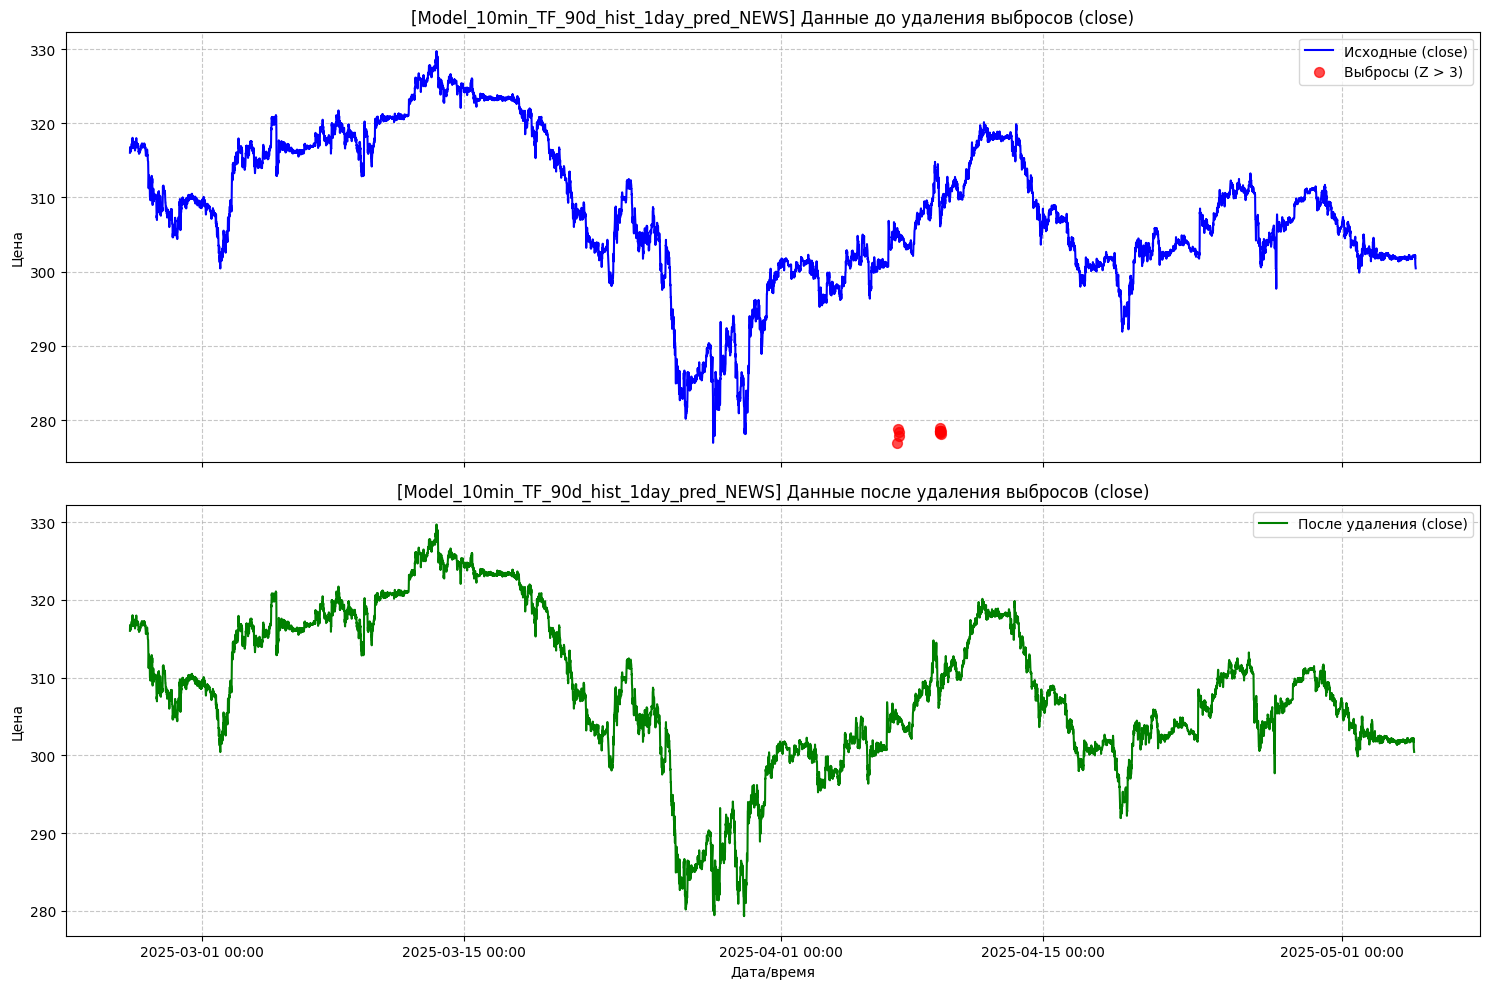

[Model_10min_TF_90d_hist_1day_pred_NEWS][PREPROCESS] Попытка интеграции новостных признаков...
[NEWS_QUERY_HELPER] Для FIGI BBG004730N88 используется поисковый запрос: "Сбербанк" OR "SBER"
[Model_10min_TF_90d_hist_1day_pred_NEWS][NEWS_PROCESSOR] Запуск обработки новостей для запроса: '"Сбербанк" OR "SBER"' (исходный идентификатор: BBG004730N88).
[Model_10min_TF_90d_hist_1day_pred_NEWS][NEWS_PROCESSOR] ВНИМАНИЕ: Запрошенная история новостей (90 дней) превышает лимит NewsAPI (28 дней для бесплатного тарифа). Новости будут запрошены начиная с 2025-04-28.
[Model_10min_TF_90d_hist_1day_pred_NEWS][NEWS_PROCESSOR] Запрошенный период для новостей (UTC naive): С: 2025-04-28 00:00:00 ПО: 2025-05-26 23:59:59
[Model_10min_TF_90d_hist_1day_pred_NEWS][NEWS_API_REQUEST] Запрос (страница 1) на URL: https://newsapi.org/v2/everything?apiKey=%2A%2A%2AAPI_KEY%2A%2A%2A&q=%22%D0%A1%D0%B1%D0%B5%D1%80%D0%B1%D0%B0%D0%BD%D0%BA%22+OR+%22SBER%22&from=2025-04-28T00%3A00%3A00&to=2025-04-28T23%3A59%3A59&language=ru&

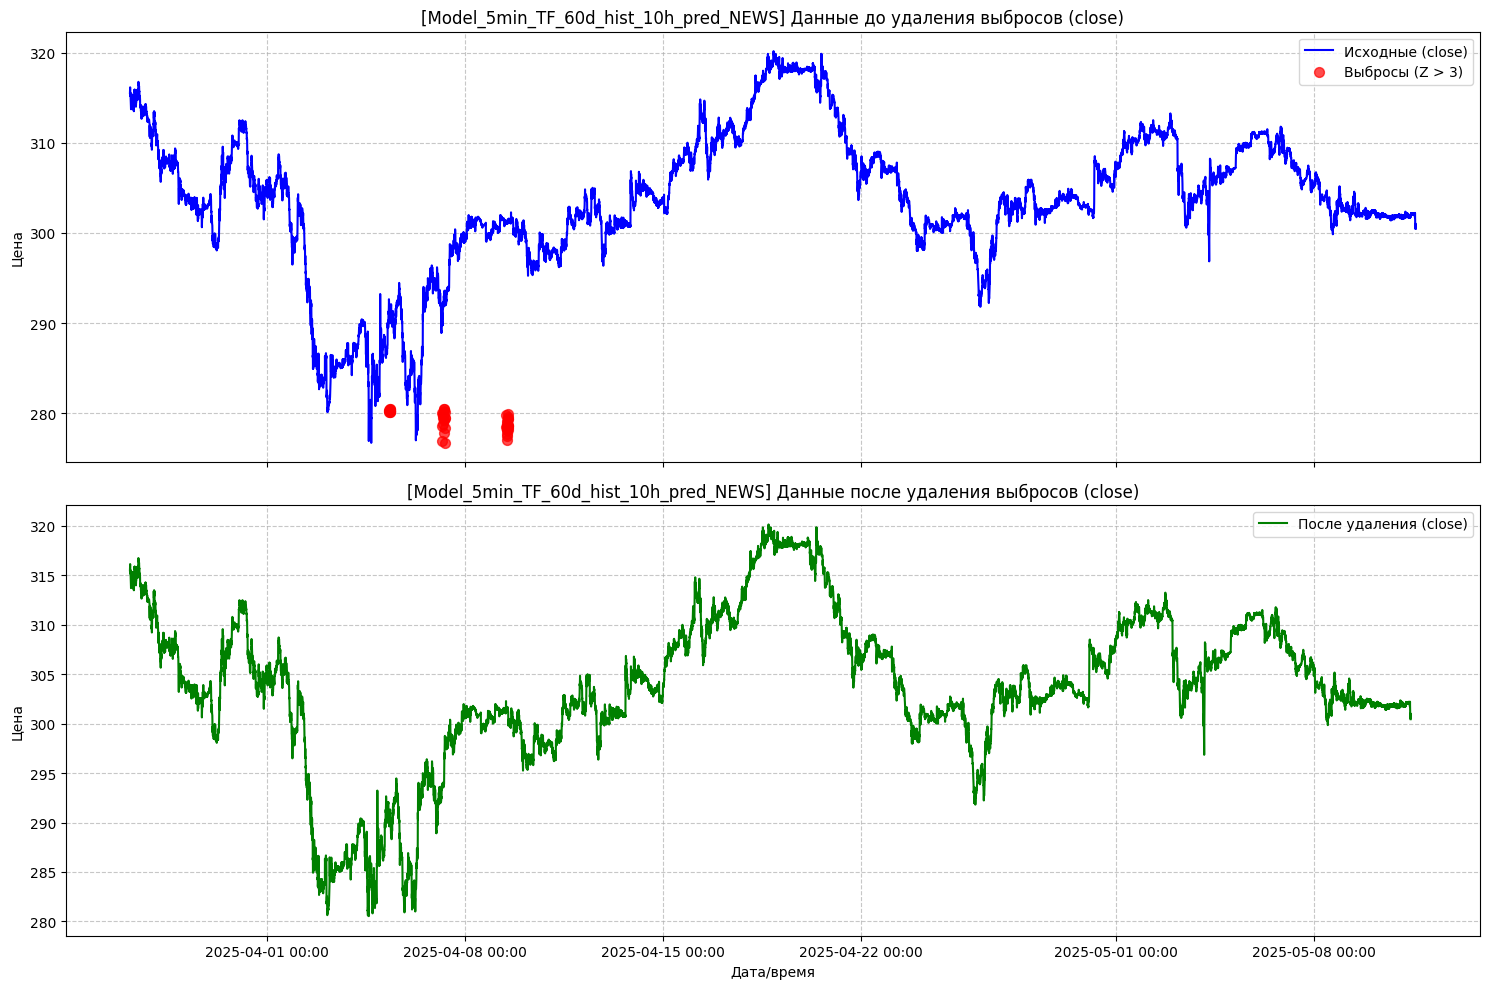

[Model_5min_TF_60d_hist_10h_pred_NEWS][PREPROCESS] Попытка интеграции новостных признаков...
[NEWS_QUERY_HELPER] Для FIGI BBG004730N88 используется поисковый запрос: "Сбербанк" OR "SBER"
[Model_5min_TF_60d_hist_10h_pred_NEWS][NEWS_PROCESSOR] Запуск обработки новостей для запроса: '"Сбербанк" OR "SBER"' (исходный идентификатор: BBG004730N88).
[Model_5min_TF_60d_hist_10h_pred_NEWS][NEWS_PROCESSOR] ВНИМАНИЕ: Запрошенная история новостей (60 дней) превышает лимит NewsAPI (28 дней для бесплатного тарифа). Новости будут запрошены начиная с 2025-04-28.
[Model_5min_TF_60d_hist_10h_pred_NEWS][NEWS_PROCESSOR] Запрошенный период для новостей (UTC naive): С: 2025-04-28 00:00:00 ПО: 2025-05-26 23:59:59
[Model_5min_TF_60d_hist_10h_pred_NEWS][NEWS_API_REQUEST] Запрос (страница 1) на URL: https://newsapi.org/v2/everything?apiKey=%2A%2A%2AAPI_KEY%2A%2A%2A&q=%22%D0%A1%D0%B1%D0%B5%D1%80%D0%B1%D0%B0%D0%BD%D0%BA%22+OR+%22SBER%22&from=2025-04-28T00%3A00%3A00&to=2025-04-28T23%3A59%3A59&language=ru&sortBy=pub

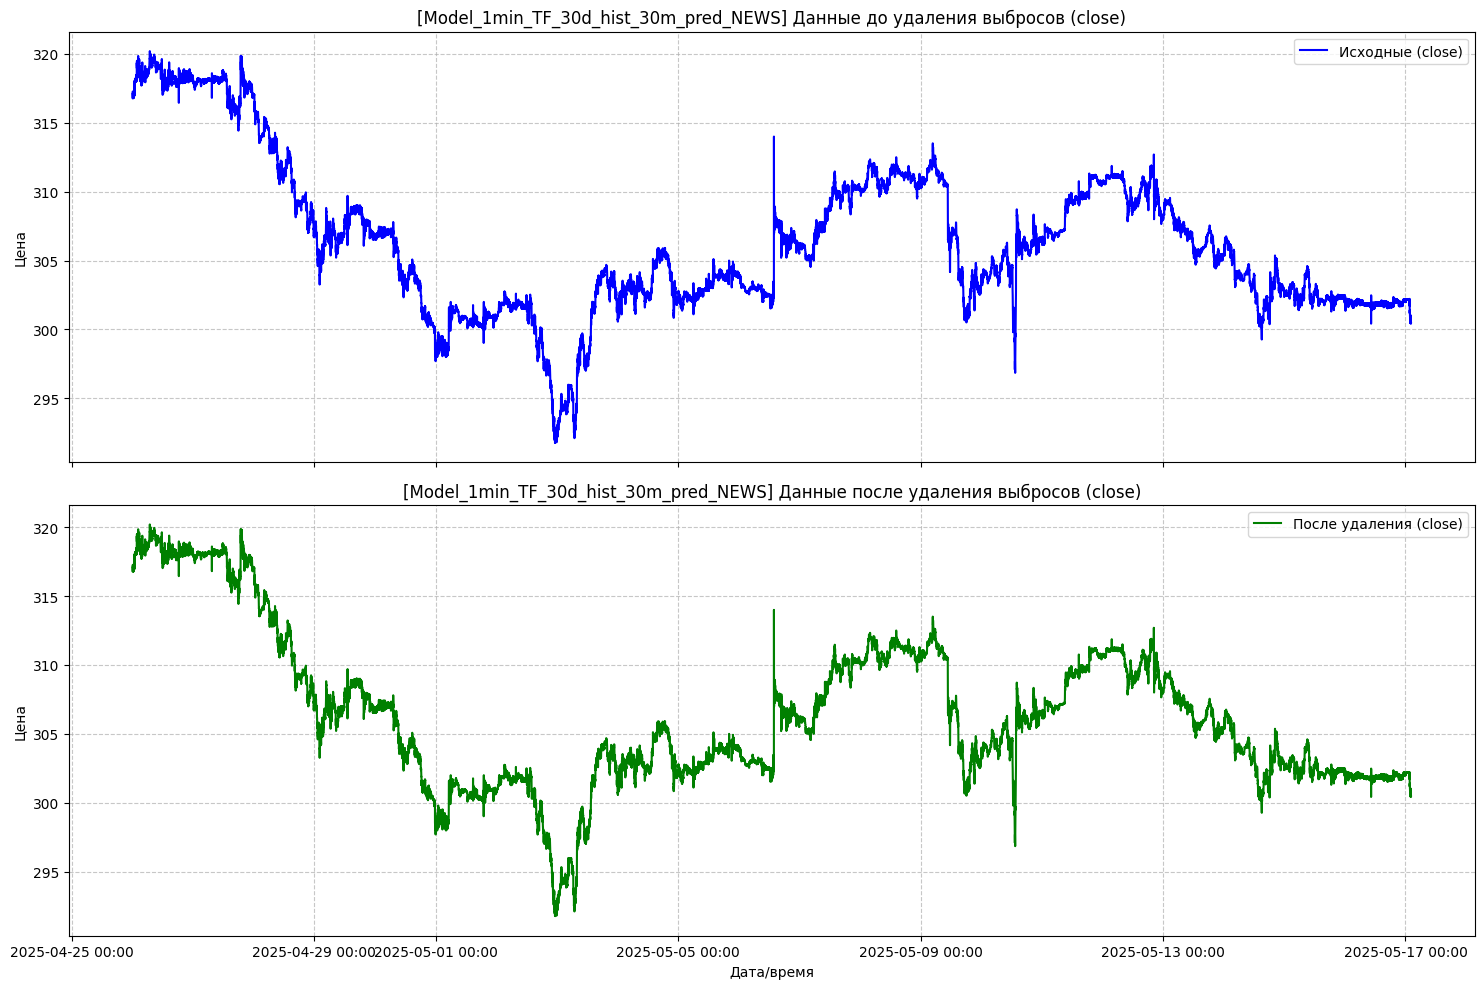

[Model_1min_TF_30d_hist_30m_pred_NEWS][PREPROCESS] Попытка интеграции новостных признаков...
[NEWS_QUERY_HELPER] Для FIGI BBG004730N88 используется поисковый запрос: "Сбербанк" OR "SBER"
[Model_1min_TF_30d_hist_30m_pred_NEWS][NEWS_PROCESSOR] Запуск обработки новостей для запроса: '"Сбербанк" OR "SBER"' (исходный идентификатор: BBG004730N88).
[Model_1min_TF_30d_hist_30m_pred_NEWS][NEWS_PROCESSOR] ВНИМАНИЕ: Запрошенная история новостей (30 дней) превышает лимит NewsAPI (28 дней для бесплатного тарифа). Новости будут запрошены начиная с 2025-04-28.
[Model_1min_TF_30d_hist_30m_pred_NEWS][NEWS_PROCESSOR] Запрошенный период для новостей (UTC naive): С: 2025-04-28 00:00:00 ПО: 2025-05-26 23:59:59
[Model_1min_TF_30d_hist_30m_pred_NEWS][NEWS_API_REQUEST] Запрос (страница 1) на URL: https://newsapi.org/v2/everything?apiKey=%2A%2A%2AAPI_KEY%2A%2A%2A&q=%22%D0%A1%D0%B1%D0%B5%D1%80%D0%B1%D0%B0%D0%BD%D0%BA%22+OR+%22SBER%22&from=2025-04-28T00%3A00%3A00&to=2025-04-28T23%3A59%3A59&language=ru&sortBy=pub

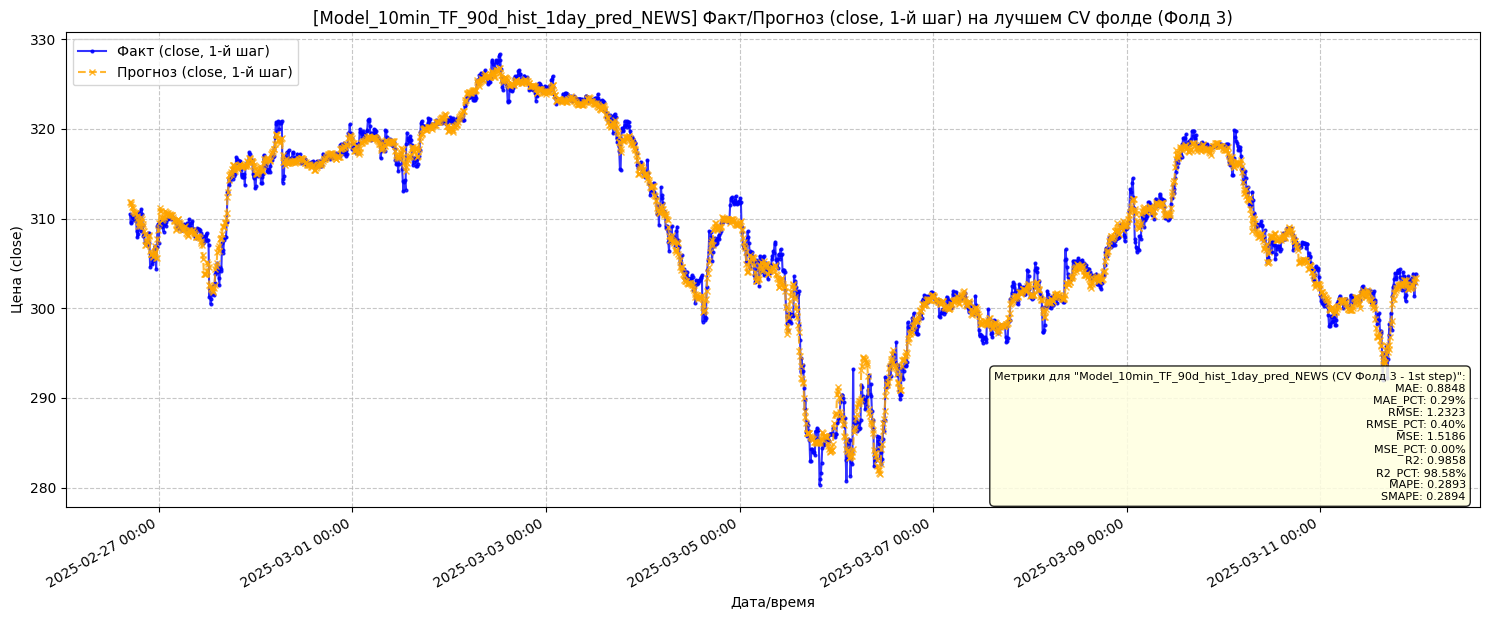


 [Model_10min_TF_90d_hist_1day_pred_NEWS][FINAL_TEST] Финальное тестирование модели 
[Model_10min_TF_90d_hist_1day_pred_NEWS][FINAL_TEST] Метрики на тестовой выборке (для 1-го шага прогноза):
  MSE: 2.0718
  RMSE: 1.4394
  MAE: 1.0487
  R2: 0.8109
  MAPE: 0.3413 %
  SMAPE: 0.3420 %
  MSE_PCT: 0.0022 %
  RMSE_PCT: 0.4703 %
  MAE_PCT: 0.3427 %
  R2_PCT: 81.0896 %


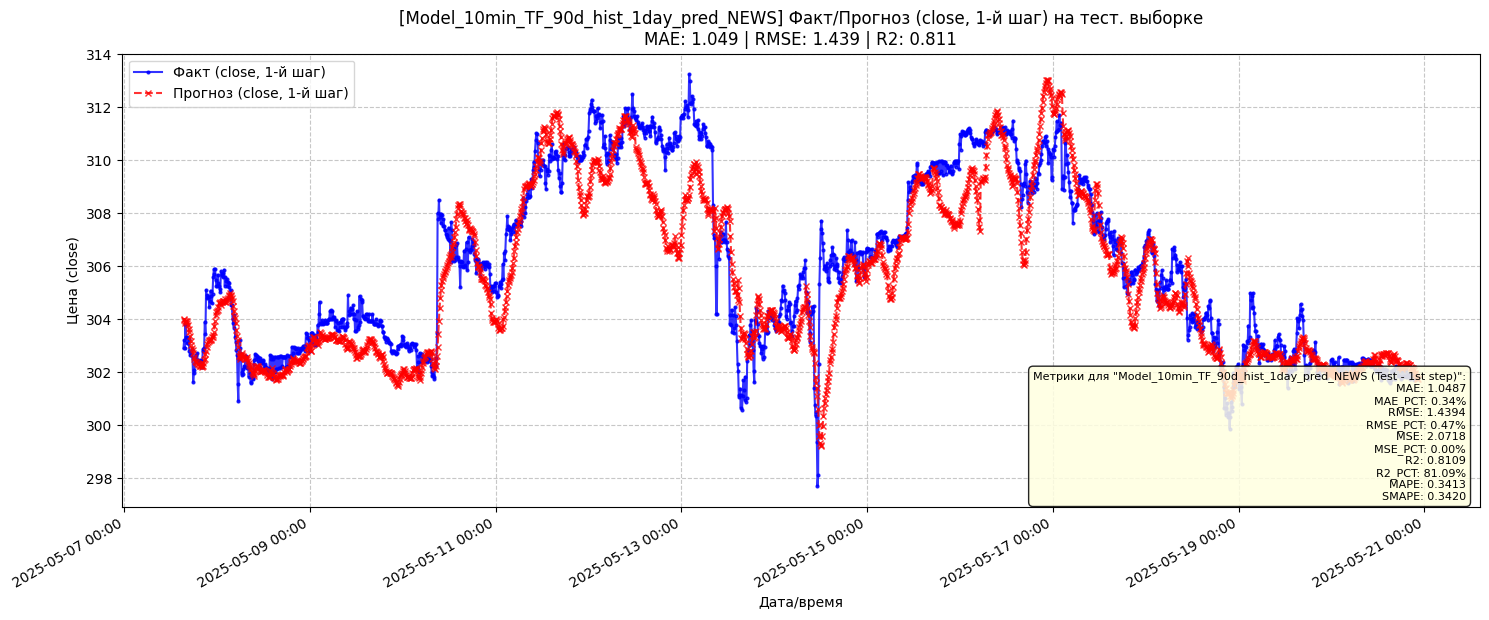

[Model_10min_TF_90d_hist_1day_pred_NEWS][FINAL_TEST] Метрики на тестовой выборке (для ПОСЛЕДНЕГО, 144-го шага прогноза):
  MSE: 22.2158
  RMSE: 4.7134
  MAE: 3.8030
  R2: -0.9204
  MAPE: 1.2423 %
  SMAPE: 1.2398 %
  MSE_PCT: 0.0237 %
  RMSE_PCT: 1.5407 %
  MAE_PCT: 1.2431 %
  R2_PCT: -92.0414 %

[Model_10min_TF_90d_hist_1day_pred_NEWS][FUTURE_PREDICT] Запуск рекурсивного прогноза на 144 шагов...
[Model_10min_TF_90d_hist_1day_pred_NEWS][FUTURE_PREDICT] n_steps_in_model_val=144, n_steps_out_model_val=144
[Model_10min_TF_90d_hist_1day_pred_NEWS][FUTURE_PREDICT] Потребуется итераций: 1
[Model_10min_TF_90d_hist_1day_pred_NEWS][FUTURE_PREDICT] Рекурсивный прогноз завершен. Предсказано 144 шагов из 144 запрошенных.

[Model_10min_TF_90d_hist_1day_pred_NEWS][FUTURE_PREDICT_RESULT] Будущие прогнозы (144/144 шагов):
                     predicted_value
datetime                            
2025-05-26 04:40:00       301.821655
2025-05-26 04:50:00       301.674011
2025-05-26 05:00:00       301.84835

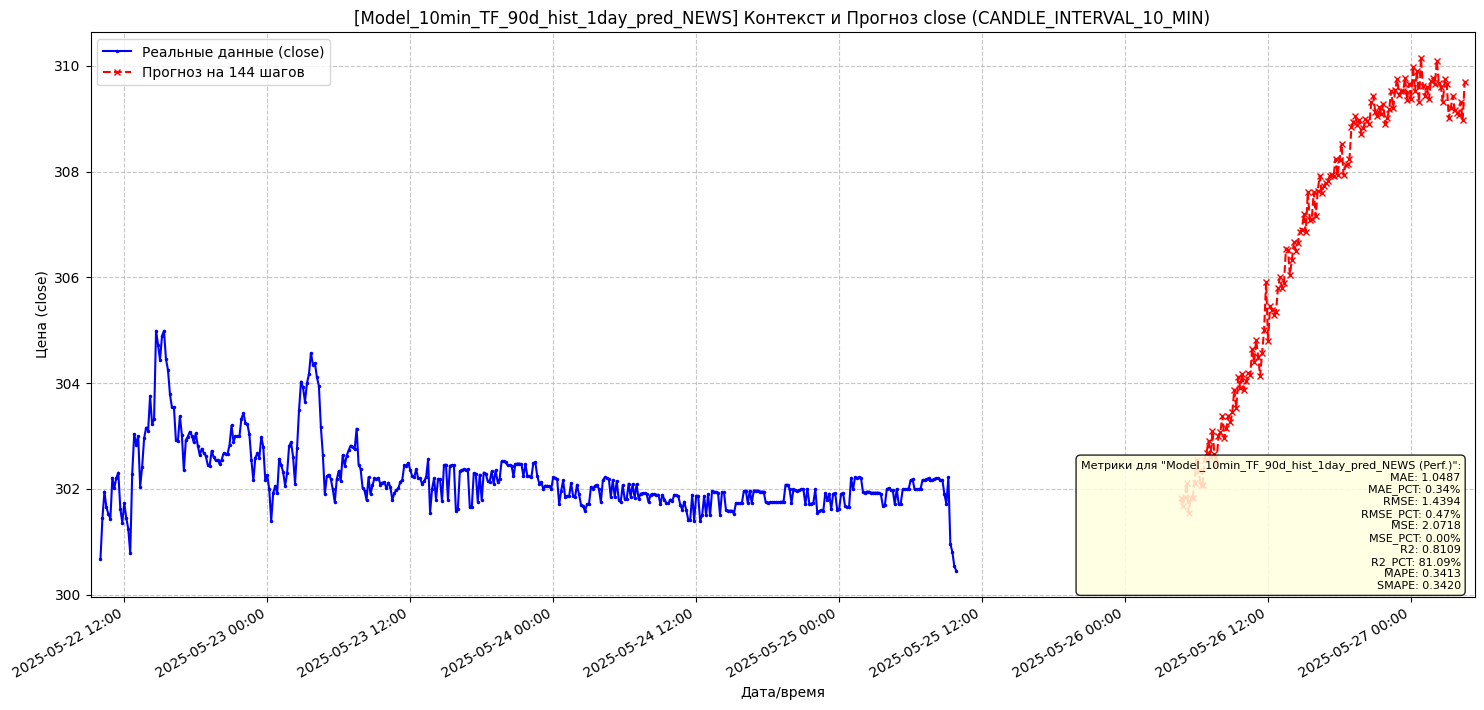


 ЗАВЕРШЕНИЕ ОБРАБОТКИ МОДЕЛИ: Model_10min_TF_90d_hist_1day_pred_NEWS 
INFO: Модель Model_10min_TF_90d_hist_1day_pred_NEWS успешно завершила обработку.



KeyboardInterrupt



In [30]:
#  ОСНОВНОЙ БЛОК ВЫПОЛНЕНИЯ
if __name__ == "__main__":
    start_time_main = time.time()
    with print_lock:
        print("======================================================")
        print(" Начало работы основной программы прогнозирования ")
        print("======================================================")
        if TINKOFF_API_TOKEN == "YOUR_TINKOFF_API_KEY":  # Используем константу из config.py или начала скрипта
            print(
                "ПРЕДУПРЕЖДЕНИЕ: TINKOFF_API_TOKEN не установлен (используется значение по умолчанию)! Загрузка данных Tinkoff не удастся.")

        # Проверка NEWSAPI_KEY
        if NEWSAPI_KEY == NEWSAPI_KEY_DEFAULT_PLACEHOLDER:
            print(
                f"ПРЕДУПРЕЖДЕНИЕ: NEWSAPI_KEY не установлен (равен плейсхолдеру '{NEWSAPI_KEY_DEFAULT_PLACEHOLDER}')! Будут использованы мок-данные для новостей.")
        elif not NEWSAPI_KEY:  # Если ключ пуст
            print("ПРЕДУПРЕЖДЕНИЕ: NEWSAPI_KEY пуст! Будут использованы мок-данные для новостей.")

    load_sentiment_model_if_needed(print_lock)  # Загружаем модель тональности заранее

    # Конфигурации моделей
    # n_steps_in: Количество прошлых временных шагов для входа
    # n_steps_out: Количество будущих временных шагов для прямого прогноза моделью
    # future_predictions: Общее количество шагов для рекурсивного прогноза
    # В конфигурациях моделей обновить параметры future_predictions:

    model_configs_list = [
        {
            "name": "Model_1min_TF_30d_hist_30m_pred_NEWS",
            "days_history": 30,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_1_MIN,
            "n_steps_in": 120,
            "n_steps_out": 30,
            "future_predictions": 30,
            "use_news_features": True
        },
        {
            "name": "Model_5min_TF_60d_hist_10h_pred_NEWS",
            "days_history": 60,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_5_MIN,
            "n_steps_in": 120,
            "n_steps_out": 60,
            "future_predictions": 120,
            "use_news_features": True
        },
        {
            "name": "Model_10min_TF_90d_hist_1day_pred_NEWS",
            "days_history": 90,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_10_MIN,
            "n_steps_in": 144,
            "n_steps_out": 144,
            "future_predictions": 144,
            "use_news_features": True
        },
    ]

    MIN_DESIRED_MODEL_WORKERS = 3
    cpu_cores_count = os.cpu_count()
    if cpu_cores_count is None:
        with print_lock:
            print(
                f"Предупреждение: Не удалось определить CPU ядер. Будет использовано до {MIN_DESIRED_MODEL_WORKERS} потоков для моделей.")
        max_cpu_based_model_workers = MIN_DESIRED_MODEL_WORKERS
    else:
        # Если есть GPU, много CPU потоков для моделей могут не дать прироста, т.к. узкое место - GPU.
        # Если нет GPU, то можно больше CPU потоков.
        # TensorFlow может не очень хорошо работать с несколькими моделями на одном GPU одновременно без careful management.
        # Оставим MIN_DESIRED_MODEL_WORKERS как основное ограничение.
        max_cpu_based_model_workers = cpu_cores_count
        with print_lock:
            print(f"Обнаружено {cpu_cores_count} CPU ядер.")

    effective_model_workers = min(len(model_configs_list), max_cpu_based_model_workers)

    # Устанавливаем максимальное количество одновременно обучаемых моделей
    # Если MIN_DESIRED_MODEL_WORKERS=0, то без ограничения (до effective_model_workers)
    MAX_MODEL_WORKERS_TO_RUN = min(effective_model_workers,
                                   MIN_DESIRED_MODEL_WORKERS) if MIN_DESIRED_MODEL_WORKERS > 0 else effective_model_workers
    MAX_MODEL_WORKERS_TO_RUN = max(1, MAX_MODEL_WORKERS_TO_RUN) if len(model_configs_list) > 0 else 0

    with print_lock:
        print(f"INFO: Запуск обучения для {len(model_configs_list)} моделей.")
        if MIN_DESIRED_MODEL_WORKERS > 0: print(
            f"INFO: Запрошено до {MIN_DESIRED_MODEL_WORKERS} параллельных потоков для моделей.")
        print(f"INFO: Максимальное количество одновременно обучаемых моделей: {MAX_MODEL_WORKERS_TO_RUN}")
        if MAX_MODEL_WORKERS_TO_RUN > 1 and gpus: print(
            "INFO: ВНИМАНИЕ! Если используется GPU, убедитесь, что TensorFlow настроен для роста памяти GPU (сделано в начале скрипта).")

    all_models_results = []  # Собираем здесь результаты от run_model_pipeline

    if len(model_configs_list) > 0 and MAX_MODEL_WORKERS_TO_RUN > 0:
        future_to_config_map = {}
        with ThreadPoolExecutor(max_workers=MAX_MODEL_WORKERS_TO_RUN, thread_name_prefix="ModelPipeline") as executor:
            for config_idx, config in enumerate(model_configs_list):
                with print_lock: print(
                    f"INFO: Отправка на выполнение модели {config_idx + 1}/{len(model_configs_list)}: {config['name']}")
                future = executor.submit(run_model_pipeline, config)
                future_to_config_map[future] = config

            for future_model_run in as_completed(future_to_config_map):
                completed_config = future_to_config_map[future_model_run]
                model_name_for_error_log = completed_config.get("name", "unknown_model")
                try:
                    model_run_output = future_model_run.result()  # Это pipeline_result
                    if model_run_output:  # Если результат не None
                        all_models_results.append(model_run_output)
                        with print_lock: print(f"INFO: Модель {model_name_for_error_log} успешно завершила обработку.")
                except Exception as e_model_pipeline:
                    with print_lock:
                        print(
                            f"КРИТИЧЕСКАЯ ОШИБКА (модель: {model_name_for_error_log}): Обработка модели завершилась с исключением: {e_model_pipeline}")
                        import traceback;

                        print(traceback.format_exc())
    elif len(model_configs_list) == 0:
        with print_lock:
            print("INFO: Нет конфигураций моделей для обучения. Завершение.")
    else:  # MAX_MODEL_WORKERS_TO_RUN == 0
        with print_lock:
            print(
                f"INFO: MAX_MODEL_WORKERS_TO_RUN ({MAX_MODEL_WORKERS_TO_RUN}) или количество моделей ({len(model_configs_list)}) равно 0. Обучение не будет запущено.")

    # -- Построение общих графиков будущих прогнозов --

    timeframe_plot_configs = [
        {"interval": CandleInterval.CANDLE_INTERVAL_1_MIN, "name": "1-минутного", "timedelta": timedelta(minutes=1)},
        {"interval": CandleInterval.CANDLE_INTERVAL_5_MIN, "name": "5-минутного", "timedelta": timedelta(minutes=5)},
        {"interval": CandleInterval.CANDLE_INTERVAL_10_MIN, "name": "10-минутного", "timedelta": timedelta(minutes=10)},
    ]

    for tf_config in timeframe_plot_configs:
        current_interval_enum = tf_config["interval"]
        current_interval_name_str = tf_config["name"]
        current_interval_td = tf_config["timedelta"]

        with print_lock:
            print(f"\n\n Построение общего графика будущих прогнозов ({current_interval_name_str} таймфрейм) ")

        predictions_for_plot_current_tf = []
        for result in all_models_results:  # result это pipeline_result
            model_tf_enum_from_result = result.get("config", {}).get("candle_timeframe")
            if model_tf_enum_from_result == current_interval_enum:
                preds_df_candidate = result.get("future_predictions_df")
                if preds_df_candidate is not None and not preds_df_candidate.empty:
                    # Получаем метрики для этой модели (тестовые предпочтительнее CV)
                    model_metrics = result.get("test_metrics") or result.get("cv_metrics")
                    predictions_for_plot_current_tf.append({
                        "name": result["model_name"],
                        "predictions": preds_df_candidate,
                        "metrics": model_metrics  # Добавляем метрики сюда
                    })

        if not predictions_for_plot_current_tf:
            with print_lock:
                print(
                    f"Не найдено данных прогнозов для {current_interval_name_str} таймфрейма для построения общего графика.")
        else:
            plt.figure(figsize=(18, 10))  # Увеличим высоту для текста метрик
            ax_combined_future = plt.gca()

            min_date_overall = None
            max_date_overall = None

            # Тексты метрик для аннотации
            all_metrics_texts_for_annotation = []

            for item in predictions_for_plot_current_tf:
                model_name = item["name"]
                preds_df = item["predictions"]  # Это DataFrame с index=datetime, column='predicted_value'
                model_item_metrics = item["metrics"]

                if not preds_df.empty:
                    current_min_date = preds_df.index.min()
                    current_max_date = preds_df.index.max()
                    if min_date_overall is None or current_min_date < min_date_overall:
                        min_date_overall = current_min_date
                    if max_date_overall is None or current_max_date > max_date_overall:
                        max_date_overall = current_max_date

                    # Для легенды используем только имя модели
                    plot_label = f'{model_name}'

                    # Используем generate_plotted_times_and_values для корректного отображения с возможными разрывами
                    # (хотя для будущих прогнозов они обычно непрерывны)
                    plotted_times, plotted_values = generate_plotted_times_and_values(
                        preds_df.index,
                        preds_df['predicted_value'].values,
                        current_interval_td,  # Таймфрейм текущего графика
                        max_gap_multiplier=1.5  # Немного больше, чтобы не разрывать случайные пропуски, если они есть
                    )
                    if len(plotted_times) > 0:
                        ax_combined_future.plot(plotted_times, plotted_values, label=plot_label, marker='.',
                                                linestyle='--', markersize=3, alpha=0.9)
                    else:  # Fallback
                        ax_combined_future.plot(preds_df.index, preds_df['predicted_value'],
                                                label=f'{plot_label} (Fallback)', marker='.', linestyle='--')

                    # Формируем строку метрик для аннотации
                    if model_item_metrics and isinstance(model_item_metrics,
                                                         dict) and model_item_metrics:  # Проверка, что не пустой словарь
                        mae = model_item_metrics.get('mae', float('nan'))
                        rmse = model_item_metrics.get('rmse', float('nan'))
                        r2 = model_item_metrics.get('r2', float('nan'))
                        metrics_line = f"{model_name}: MAE={mae:.3f}, RMSE={rmse:.3f}, R2={r2:.3f}"
                        all_metrics_texts_for_annotation.append(metrics_line)
                    else:
                        all_metrics_texts_for_annotation.append(f"{model_name}: Метрики н/д")

            plt.title(f'Общий график будущих прогнозов для {INSTRUMENT_FIGI} ({current_interval_name_str} таймфрейм)',
                      fontsize=14)
            plt.xlabel('Дата/время будущего периода', fontsize=12)
            plt.ylabel(f'Прогнозируемая цена ({FEATURE_COLUMN})', fontsize=12)

            if min_date_overall and max_date_overall:
                padding = current_interval_td * 10
                if pd.isna(min_date_overall): min_date_overall = datetime.now() - timedelta(hours=1)  # Fallback
                if pd.isna(max_date_overall): max_date_overall = datetime.now()  # Fallback
                ax_combined_future.set_xlim([min_date_overall - padding, max_date_overall + padding])

            if all_metrics_texts_for_annotation:
                full_metrics_summary_text = "Сводка по моделям (Test/CV показатели):\n" + "\n".join(
                    all_metrics_texts_for_annotation)
                ax_combined_future.text(0.01, 0.99, full_metrics_summary_text,
                                        transform=ax_combined_future.transAxes,
                                        fontsize=8, verticalalignment='top', horizontalalignment='left',
                                        bbox=dict(boxstyle='round,pad=0.4', fc='ivory', alpha=0.88))

            ax_combined_future.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
            ax_combined_future.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=7, maxticks=15))
            plt.xticks(rotation=30, ha="right")
            plt.legend(loc='best', fontsize=9)
            plt.grid(True, linestyle=':', alpha=0.6)
            plt.tight_layout(rect=[0, 0.03, 1, 0.95]);
            plt.show()
            with print_lock:
                print(f"Общий график будущих прогнозов для {current_interval_name_str} таймфрейма отображен.")

    end_time_main = time.time()
    total_duration_main = end_time_main - start_time_main
    with print_lock:
        print("\n======================================================")
        print(f" Работа всей программы прогнозирования завершена за {total_duration_main:.2f} секунд.")
        print("======================================================")
